# Notebook 07 · Recommandations marketing : comment se servir du score

**La question du directeur marketing** : « Je peux écrire à 10 % de la base. À qui, avec quoi, quand, et est-ce que ça rapporte ? »

**Fil conducteur**
1. **Le top 10 % par score** : ce qu'il apporte face au hasard, à la règle de récence et au score RFM (précision, rappel, lift, rachats « captés »).
2. **Un seul segment pour l'oral** : on croise les segments du notebook 05 avec les scores du modèle, puis on confirme ou on nuance le choix de « Good ».
3. **Le segment retenu** : persona, leviers (timing, rythme d'achat, week-end), message, canal, calendrier.
4. **Scénarios économiques** : le ciblage par score rapporte-t-il plus qu'un ciblage aléatoire ? Seuil de rentabilité et seuil de remise.
5. **Test A/B** : taille d'échantillon, groupe témoin, KPI, durée, plan d'action en 3 étapes.
6. **Limites et risques** : un score de propension n'est pas un effet causal.

**Deux règles de lecture, tout au long du notebook**
- 🟦 **MESURÉ** : calculé dans les données (rachat observé en août 2020 sur le train, scores hors-échantillon par validation croisée). Les scores ne servent jamais à fixer un seuil sur le test.
- 🟧 **SUPPOSÉ** : hypothèse de scénario (coût de contact, marge, remise, uplift). Les hypothèses sont rassemblées dans un seul dictionnaire, modifiable, et chaque tableau économique le rappelle.

**Lien avec le cours** : ciblage, personnalisation, test A/B avec groupe témoin, seuil de remise, suivi du modèle (slides 74-76, 89) ; RFM (slides 23-28). Même esprit que le Projet 1 : leviers chiffrés, hypothèses explicites, plan d'action priorisé.

In [1]:
import os, re, json, warnings
os.environ.update(OMP_NUM_THREADS='2', OPENBLAS_NUM_THREADS='2', VECLIB_MAXIMUM_THREADS='2', MKL_NUM_THREADS='2')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
threadpool_limits(2)          # machine partagée : 2 fils au plus
import common as c
import segments as sg
c.set_style()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def fr(x, d=0):               # 12 345,6 (espace insécable, virgule décimale)
    return f"{x:,.{d}f}".replace(',', ' ').replace('.', ',')
def pc(x, d=1):               # x déjà en %
    return f"{x:.{d}f} %".replace('.', ',')
def dec(t):                   # 0.55 -> 0,55 (uniquement entre deux chiffres)
    return re.sub(r'(?<=\d)\.(?=\d)', ',', t)
def say(t): display(Markdown(dec(t)))
def savefig(fig, name):
    c.save_fig(fig, name); plt.show()
def show(df, precision=2, cols=None):   # tableau : espace pour les milliers, virgule décimale, entiers sans décimale
    fmt = {}
    for col in df.columns:
        v = pd.to_numeric(df[col], errors='coerce')
        if not v.notna().any() or v.isna().sum() > df[col].isna().sum():
            continue                                      # colonne de texte : laissée telle quelle
        vv = v.dropna()
        d = 0 if (vv == vv.round()).all() else (cols or {}).get(col, precision)
        fmt[col] = (lambda d_: (lambda x: fr(x, d_) if pd.notna(x) else ''))(d)
    display(df.style.format(fmt))

MODEL = 'lgbm_tuned'          # score du notebook 04 ; le notebook 06 fournira `final_lgbm` : il suffit de changer ce nom
BENCH = {'Règle de récence': 'recency_rule', 'Score RFM': 'rfm_score',
         'Régression logistique (Lasso)': 'logreg_lasso', 'LightGBM réglé': MODEL}
SEED = c.SEED
rng = np.random.RandomState(SEED)

In [2]:
Xtr, Xte = c.load_features('train'), c.load_features('test')
y = c.load_target().reindex(Xtr.index)
base = y.mean()
score = c.load_predictions(MODEL)[0].reindex(Xtr.index)
pred = {k: c.load_predictions(v)[0].reindex(Xtr.index) for k, v in BENCH.items()}
email = Xtr['has_email'].astype(bool)
email_te = Xte['has_email'].astype(bool)
seg = sg.assign_rfm(Xtr).astype(str)
seg_te = sg.assign_rfm(Xte).astype(str)
N, N_FULL = len(Xtr), len(Xtr) + len(Xte)            # base complète = train + test (le test est un tirage de 20 %)
K10 = int(round(c.TOP_FRAC * N))                      # 10 % de la base train
K10_FULL = int(round(c.TOP_FRAC * N_FULL))            # 10 % de la base complète
rank = score.rank(ascending=False, method='first')   # rang 1 = meilleur score
say(f"**Base d'étude** : train {fr(N)} clients (rachat en août 2020 : **{pc(100*base, 2)}**, {fr(y.sum())} rachats), test {fr(len(Xte))} clients sans cible. "
    f"La base complète compte {fr(N_FULL)} clients : 10 % = **{fr(K10_FULL)} clients** à contacter au maximum (soit {fr(K10)} sur le train). "
    f"Modèle de score : `{MODEL}` (prédictions hors-échantillon, validation croisée 5 plis du notebook 04). "
    f"Part de clients joignables par e-mail : {pc(100*email.mean())} (train).")

**Base d'étude** : train 160 424 clients (rachat en août 2020 : **7,72 %**, 12 392 rachats), test 40 106 clients sans cible. La base complète compte 200 530 clients : 10 % = **20 053 clients** à contacter au maximum (soit 16 042 sur le train). Modèle de score : `lgbm_tuned` (prédictions hors-échantillon, validation croisée 5 plis du notebook 04). Part de clients joignables par e-mail : 54,7 % (train).

## 1. Cibler le top 10 % : que gagne-t-on face au hasard, à la récence, au RFM ?

**Définitions** (top 10 % = les 10 % de clients au meilleur score de chaque méthode ; rachat = achat en août 2020) :
- **Précision** : part des clients ciblés qui rachètent. **Rappel** : part de tous les racheteurs qui sont dans la cible. **Lift** : précision ÷ taux de rachat moyen de la base.
- **Rachats captés** : nombre de racheteurs dans la cible. **Rachats captés en plus du hasard** : captés − (nombre de clients ciblés × taux moyen).
- ⚠ « Capté » ne veut pas dire « provoqué » : ces clients auraient acheté sans e-mail. Le gain *causal* de la campagne se mesure par un test A/B (section 5).

Les intervalles de confiance viennent d'un **bootstrap des clients** (300 tirages, le top 10 % est recalculé à chaque tirage). 🟦 *Tout est mesuré.*

In [3]:
def top_hits(s, yv, k):
    # nombre de racheteurs dans les k meilleurs scores (départage par l'ordre d'apparition, comme c.topk_metrics)
    return yv[np.argsort(-s, kind='stable')[:k]].sum()

yv = y.values
rows, boot = [], {}
B = 300
svals = {n_: s_.values for n_, s_ in pred.items()}
hits_b = {n_: np.zeros(B) for n_ in pred}; base_b = np.zeros(B)
for b_ in range(B):
    ix = rng.randint(0, N, N); yb = yv[ix]; base_b[b_] = yb.mean()
    for n_, sv_ in svals.items():
        hits_b[n_][b_] = top_hits(sv_[ix], yb, K10)
for name, s in pred.items():
    sv = s.values
    m = c.topk_metrics(yv, sv)
    boot[name] = dict(prec=hits_b[name] / K10, extra=hits_b[name] - K10 * base_b)
    # variante : 10 % de la base choisis parmi les seuls clients joignables par e-mail
    se = pd.Series(sv, index=Xtr.index)[email]
    ie = se.index[np.argsort(-se.values, kind='stable')[:K10]]
    rows.append(dict(méthode=name, n_cibles=m['k'], précision=100 * m['precision'],
                     prec_bas=100 * np.percentile(boot[name]['prec'], 2.5), prec_haut=100 * np.percentile(boot[name]['prec'], 97.5),
                     rappel=100 * m['recall'], lift=m['lift'], rachats_captés=m['precision'] * K10,
                     captés_en_plus=m['precision'] * K10 - K10 * base,
                     extra_bas=np.percentile(boot[name]['extra'], 2.5), extra_haut=np.percentile(boot[name]['extra'], 97.5),
                     pct_joignables=100 * email[s.index[np.argsort(-sv, kind='stable')[:K10]]].mean(),
                     précision_si_email_seul=100 * y[ie].mean(), rappel_si_email_seul=100 * y[ie].sum() / y.sum()))
# hasard : espérance exacte ; IC binomial de Wilson
lo, hi = proportion_confint(round(base * K10), K10, method='wilson')
rows.insert(0, dict(méthode='Ciblage aléatoire', n_cibles=K10, précision=100 * base, prec_bas=100 * lo, prec_haut=100 * hi,
                    rappel=100 * c.TOP_FRAC, lift=1.0, rachats_captés=base * K10, captés_en_plus=0.0, extra_bas=0.0, extra_haut=0.0,
                    pct_joignables=100 * email.mean(), précision_si_email_seul=100 * y[email].mean(),
                    rappel_si_email_seul=100 * K10 * y[email].mean() / y.sum()))
T1 = pd.DataFrame(rows).set_index('méthode')
T1_show = T1[['n_cibles', 'précision', 'prec_bas', 'prec_haut', 'rappel', 'lift', 'rachats_captés', 'captés_en_plus', 'extra_bas', 'extra_haut', 'pct_joignables', 'précision_si_email_seul']].round(1)
T1_show.columns = ['Clients ciblés', 'Précision %', 'IC95 bas', 'IC95 haut', 'Rappel %', 'Lift', 'Rachats captés', 'Captés en plus du hasard', 'Captés en plus : IC95 bas', 'Captés en plus : IC95 haut', '% joignables e-mail', 'Précision % (10 % choisis parmi les e-mailables)']
show(T1_show, precision=1)

,Clients ciblés,Précision %,IC95 bas,IC95 haut,Rappel %,Lift,Rachats captés,Captés en plus du hasard,Captés en plus : IC95 bas,Captés en plus : IC95 haut,% joignables e-mail,Précision % (10 % choisis parmi les e-mailables)
méthode,,,,,,,,,,,,
Ciblage aléatoire,16 042,"7,7","7,3","8,1","10,0","1,0","1 239,2","0,0","0,0","0,0","54,7","8,8"
Règle de récence,16 042,"23,5","22,8","24,2","30,4","3,0","3 766,0","2 526,8","2 431,8","2 621,5","60,9","23,0"
Score RFM,16 042,"32,7","32,0","33,5","42,3","4,2","5 246,0","4 006,8","3 902,8","4 131,7","65,4","28,8"
Régression logistique (Lasso),16 042,"39,3","38,6","40,2","50,9","5,1","6 308,0","5 068,8","4 965,6","5 182,7","64,8","31,5"
LightGBM réglé,16 042,"40,6","39,9","41,4","52,6","5,3","6 521,0","5 281,8","5 177,7","5 399,2","64,1","32,3"


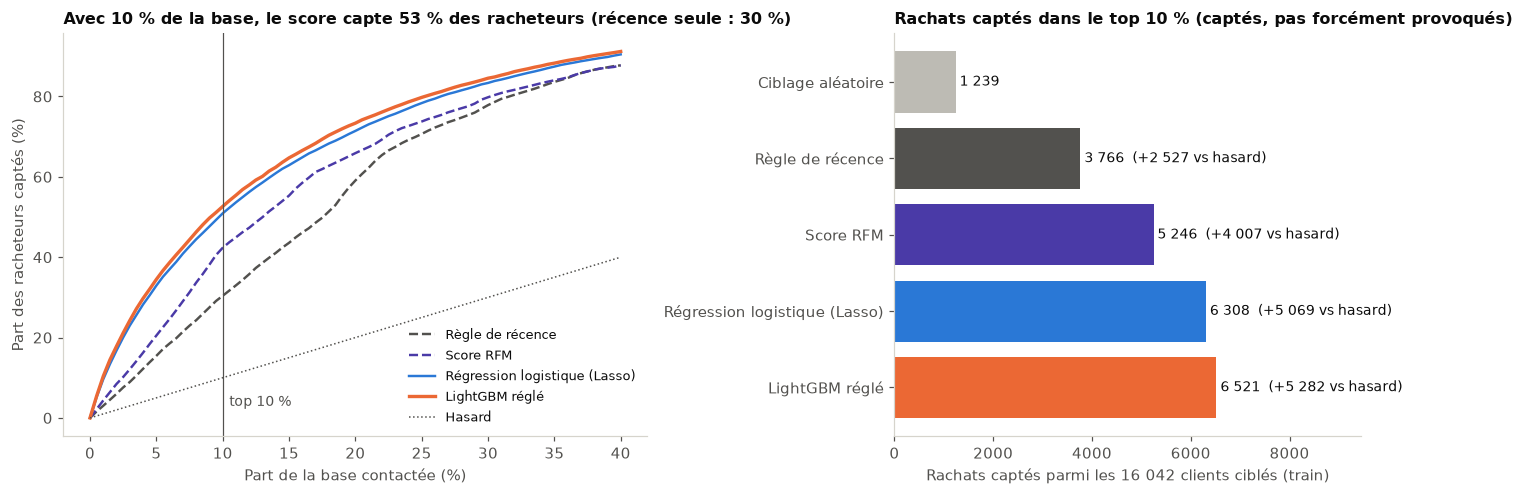

In [4]:
# courbes de gain (part des racheteurs captés selon la part de base ciblée) et rachats captés
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
fr_grid = np.linspace(0, 0.4, 81)
styles = {'Règle de récence': (c.INK2, '--'), 'Score RFM': (c.PURPLE, '--'), 'Régression logistique (Lasso)': (c.BLUE, '-'), 'LightGBM réglé': (c.ACCENT, '-')}
for name, s in pred.items():
    o = np.argsort(-s.values, kind='stable'); cum = np.concatenate([[0], np.cumsum(yv[o])]) / yv.sum()
    ax.plot(fr_grid * 100, [cum[int(round(f * N))] * 100 for f in fr_grid], color=styles[name][0], ls=styles[name][1], lw=2.2 if name == 'LightGBM réglé' else 1.6, label=name)
ax.plot(fr_grid * 100, fr_grid * 100, color=c.INK2, lw=1, ls=':', label='Hasard')
ax.axvline(10, color=c.INK2, lw=0.8); ax.text(10.5, 3, 'top 10 %', color=c.INK2, fontsize=9)
ax.set_xlabel('Part de la base contactée (%)'); ax.set_ylabel('Part des racheteurs captés (%)')
ax.set_title(f"Avec 10 % de la base, le score capte {pc(T1.loc['LightGBM réglé','rappel'], 0)} des racheteurs (récence seule : {pc(T1.loc['Règle de récence','rappel'], 0)})", fontsize=10.5, loc='left')
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax = axes[1]
names = ['Ciblage aléatoire'] + list(pred)
vals = [T1.loc[n_, 'rachats_captés'] for n_ in names]
cols = [c.GREY, c.INK2, c.PURPLE, c.BLUE, c.ACCENT]
bars = ax.barh(names[::-1], vals[::-1], color=cols[::-1])
for b_, n_ in zip(bars, names[::-1]):
    v = T1.loc[n_, 'rachats_captés']; e = T1.loc[n_, 'captés_en_plus']
    ax.text(v + 80, b_.get_y() + b_.get_height() / 2, f"{fr(v)}" + (f"  (+{fr(e)} vs hasard)" if e > 0 else ''), va='center', fontsize=9)
ax.set_xlim(0, max(vals) * 1.45); ax.set_xlabel(f"Rachats captés parmi les {fr(K10)} clients ciblés (train)")
ax.set_title('Rachats captés dans le top 10 % (captés, pas forcément provoqués)', fontsize=10.5, loc='left')
fig.tight_layout(); savefig(fig, '07_ciblage_top10')

In [5]:
best, rec = T1.loc['LightGBM réglé'], T1.loc['Règle de récence']
d_boot = boot['LightGBM réglé']['prec'] - boot['Règle de récence']['prec']
d_boot_l = boot['LightGBM réglé']['prec'] - boot['Régression logistique (Lasso)']['prec']
say(f"""**Lecture** (train, {fr(K10)} clients ciblés, hors-échantillon)
- Le score LightGBM cible avec **{pc(best['précision'])} de précision** (lift {best['lift']:.2f}) et capte **{pc(best['rappel'])} des racheteurs** ; un tirage au hasard donne {pc(T1.loc['Ciblage aléatoire','précision'])}.
  Cela fait **{fr(best['rachats_captés'])} racheteurs captés, soit {fr(best['captés_en_plus'])} de plus que le hasard** (IC95 : {fr(best['extra_bas'])} à {fr(best['extra_haut'])}).
- Face à la **règle de récence** (précision {pc(rec['précision'])}), le modèle gagne **{(best['précision']-rec['précision']):.1f} points de précision** (IC95 de l'écart : {100*np.percentile(d_boot,2.5):.1f} à {100*np.percentile(d_boot,97.5):.1f}), soit {fr(best['rachats_captés']-rec['rachats_captés'])} racheteurs captés en plus.
  Le score **RFM** à 13 niveaux (précision {pc(T1.loc['Score RFM','précision'])}) est entre les deux : il perd l'information fine sur le rythme et la part de week-end.
- Face à la **logistique Lasso**, l'écart est de {(best['précision']-T1.loc['Régression logistique (Lasso)','précision']):.1f} point (IC95 : {100*np.percentile(d_boot_l,2.5):.1f} à {100*np.percentile(d_boot_l,97.5):.1f}) : petit mais stable ; la logistique reste une alternative lisible.
- **Joignabilité** : seuls {pc(best['pct_joignables'], 0)} des clients du top 10 % ont une adresse e-mail. Si l'on choisit les 10 % de clients *parmi les e-mailables*, la précision passe de {pc(best['précision'])} à **{pc(best['précision_si_email_seul'])}** (rappel {pc(best['rappel_si_email_seul'], 0)} de *tous* les racheteurs) :
  c'est la vraie performance d'une campagne e-mail, et c'est ce que nous retiendrons pour les scénarios économiques.
- ⚠ Les e-mailables rachètent plus ({pc(100*y[email].mean())} contre {pc(100*y[~email].mean())}) : c'est une **sélection**, pas un effet de l'e-mail (ce sont des clients mieux identifiés, plus fidèles).""")

**Lecture** (train, 16 042 clients ciblés, hors-échantillon)
- Le score LightGBM cible avec **40,6 % de précision** (lift 5,26) et capte **52,6 % des racheteurs** ; un tirage au hasard donne 7,7 %.
  Cela fait **6 521 racheteurs captés, soit 5 282 de plus que le hasard** (IC95 : 5 178 à 5 399).
- Face à la **règle de récence** (précision 23,5 %), le modèle gagne **17,2 points de précision** (IC95 de l'écart : 16,5 à 17,9), soit 2 755 racheteurs captés en plus.
  Le score **RFM** à 13 niveaux (précision 32,7 %) est entre les deux : il perd l'information fine sur le rythme et la part de week-end.
- Face à la **logistique Lasso**, l'écart est de 1,3 point (IC95 : 1,0 à 1,7) : petit mais stable ; la logistique reste une alternative lisible.
- **Joignabilité** : seuls 64 % des clients du top 10 % ont une adresse e-mail. Si l'on choisit les 10 % de clients *parmi les e-mailables*, la précision passe de 40,6 % à **32,3 %** (rappel 42 % de *tous* les racheteurs) :
  c'est la vraie performance d'une campagne e-mail, et c'est ce que nous retiendrons pour les scénarios économiques.
- ⚠ Les e-mailables rachètent plus (8,8 % contre 6,4 %) : c'est une **sélection**, pas un effet de l'e-mail (ce sont des clients mieux identifiés, plus fidèles).

## 2. Un seul segment pour l'oral : croiser les segments (notebook 05) avec le score

Le sujet impose de **se concentrer sur un segment**. Le notebook 05 recommandait **Good** (taux de rachat sous la moyenne de la base, lift inférieur à 1, mais un grand segment e-mailable) ; second choix **C3 Montants**. Ce choix reposait sur le seul comportement passé.
Maintenant que le modèle existe, trois questions :
1. **Où se trouvent les segments dans le classement du modèle ?** (part du segment dans le top 10 % et le top 30 % ; distribution des scores)
2. **Le score distingue-t-il les clients *à l'intérieur* du segment ?** (AUC intra-segment : sans variation de score, le ciblage dans le segment n'apporte rien)
3. **Quelle valeur en jeu ?** Rachats attendus, rachats « hors top 10 % » (ceux que le ciblage par score laisse de côté), et valeur sous les scénarios 🟧 de la section 4.

Les classes du clustering sont ré-estimées avec les mêmes réglages que le notebook 05 (K-Means, k = 6, graine 42) : on vérifie qu'on retrouve les mêmes effectifs.

In [6]:
# ---------------------------------------------------------------------------------------------------------------
# 🟧 HYPOTHÈSES DU SCÉNARIO ÉCONOMIQUE (SUPPOSÉES : aucune n'est lue dans les données ; à modifier librement)
# ---------------------------------------------------------------------------------------------------------------
ASSUME = {
    'contact_cost':  0.02,   # € par e-mail envoyé (plateforme d'envoi + création, hors « fatigue » du client)       SUPPOSÉ
    'margin':        0.25,   # marge brute en % du panier (supermarché, avant remise)                                 SUPPOSÉ
    'discount':      0.10,   # remise offerte dans l'e-mail : 10 % du panier                                          SUPPOSÉ
    'redeem':        0.30,   # part des acheteurs du mois (de base ou supplémentaires) qui utilisent la remise : l'offre dure 7 jours sur ~30, donc un acheteur « naturel » sur trois environ en profite   SUPPOSÉ
    'uplift_abs':    {'bas': 0.005, 'central': 0.010, 'haut': 0.020},   # uplift ABSOLU : points de rachat gagnés    SUPPOSÉ
    'uplift_rel':    {'bas': 0.05,  'central': 0.10,  'haut': 0.20},    # uplift RELATIF : % du taux de base         SUPPOSÉ
}
# MESURÉ dans les données : taux de rachat (cible), panier moyen du client (moyenne des tickets sur 12 mois, `basket_mean_all`),
# effectifs de segments, scores hors-échantillon.

def net_per_contact(p, b, u, mode='abs', a=ASSUME, discount=None):
    # Marge nette espérée par client contacté.
    #  p : taux de rachat de base du groupe ciblé (MESURÉ)   b : panier moyen (MESURÉ)   u : uplift (SUPPOSÉ)
    #  mode 'abs' : le rachat gagne u points pour tous (le score n'aide pas à trouver les « influençables »)
    #  mode 'rel' : le rachat est multiplié par (1+u) (hypothèse favorable au score : plus de rachat de base = plus de gain)
    d = a['discount'] if discount is None else discount
    inc = u if mode == 'abs' else p * u                 # rachats supplémentaires par client contacté
    buyers = p + u if mode == 'abs' else p * (1 + u)    # acheteurs de la période, toutes causes confondues
    margin_inc = inc * b * a['margin']                  # marge sur les achats provoqués
    disc_cost = a['redeem'] * buyers * d * b            # remise accordée à TOUS ceux qui l'utilisent, y compris ceux qui auraient acheté de toute façon (cannibalisation)
    net = margin_inc - disc_cost - a['contact_cost']
    return dict(net=net, margin_inc=margin_inc, disc_cost=disc_cost, cost=disc_cost + a['contact_cost'], inc=inc)

def breakeven_uplift(p, b, mode='abs', a=ASSUME):
    # Uplift minimal pour que la marge nette soit nulle
    d, r, m, cc = a['discount'], a['redeem'], a['margin'], a['contact_cost']
    u = (cc + r * p * d * b) / (b * (m - r * d))
    return u if mode == 'abs' else u / p

def max_discount(p, b, u, mode='abs', a=ASSUME):
    # Remise maximale (seuil de remise) qui laisse une marge nette nulle pour un uplift u donné
    r, m, cc = a['redeem'], a['margin'], a['contact_cost']
    if mode == 'abs':
        return (u * b * m - cc) / (r * (p + u) * b)
    return (p * u * b * m - cc) / (r * p * (1 + u) * b)

say("**Hypothèses 🟧 chargées** : coût de contact " + f"{ASSUME['contact_cost']} €, marge brute {pc(100*ASSUME['margin'],0)}, remise {pc(100*ASSUME['discount'],0)} du panier, utilisation de la remise par {pc(100*ASSUME['redeem'],0)} des acheteurs ; "
    f"uplift absolu (bas / central / haut) : {' / '.join(f'+{100*v:.1f} pt' for v in ASSUME['uplift_abs'].values())} ; "
    f"uplift relatif : {' / '.join(f'+{100*v:.0f} %' for v in ASSUME['uplift_rel'].values())}.")

**Hypothèses 🟧 chargées** : coût de contact 0,02 €, marge brute 25 %, remise 10 % du panier, utilisation de la remise par 30 % des acheteurs ; uplift absolu (bas / central / haut) : +0,5 pt / +1,0 pt / +2,0 pt ; uplift relatif : +5 % / +10 % / +20 %.

In [7]:
# clustering du notebook 05 (mêmes réglages : 9 variables, ACP à 80 %, K-Means k = 6, graine 42)
cl_model = sg.fit_clusters(Xtr, 6, variance=0.80, seed=SEED)
cl_tr = sg.assign_clusters(Xtr, cl_model)
cnames = sg.cluster_names(Xtr, cl_tr)
cl_tr_n = cl_tr.map(cnames); cl_te_n = sg.assign_clusters(Xte, cl_model).map(cnames)
ref05 = pd.read_csv(c.RES / '05_candidate_segments.csv').set_index('segment')
chk = pd.DataFrame({'effectif recalculé': cl_tr_n.value_counts(), 'effectif notebook 05': ref05['n_clients']}).dropna()
say(f"**Contrôle de reproductibilité** : écart maximal d'effectif avec le notebook 05 sur les 6 classes = {int((chk.iloc[:,0]-chk.iloc[:,1]).abs().max())} client(s).")

**Contrôle de reproductibilité** : écart maximal d'effectif avec le notebook 05 sur les 6 classes = 0 client(s).

In [8]:
basket = Xtr['basket_mean_all']
def seg_row(mask_tr, mask_te):
    m = mask_tr.values; me = m & email.values
    s_in = score[m]
    row = dict(n_train=int(m.sum()), n_base_complète=int(m.sum() + mask_te.sum()),
               n_email_complète=int(me.sum() + (mask_te & email_te).sum()),
               rachat=100 * y[m].mean(), rachat_email=100 * y[me].mean(),
               auc_intra=roc_auc_score(y[m], s_in), score_médian=100 * s_in.median(), score_p90=100 * s_in.quantile(0.9),
               part_top10=100 * (rank[m] <= K10).mean(), part_top30=100 * (rank[m] <= 0.3 * N).mean(),
               rachats=int(y[m].sum()), pct_rachats=100 * y[m].sum() / y.sum(),
               captés_top10=100 * y[m & (rank <= K10).values].sum() / max(y[m].sum(), 1),
               panier=basket[me].mean(), ca_client=Xtr['spend_all'][m].mean(), score_moyen_email=100 * score[me].mean())
    return row

cands = {n: (seg == n, seg_te == n) for n in sg.SEGMENT_ORDER}
cands.update({n: (cl_tr_n == n, cl_te_n == n) for n in sorted(cl_tr_n.unique())})
T2 = pd.DataFrame({n: seg_row(*m) for n, m in cands.items()}).T
T2 = T2.apply(pd.to_numeric)

# valeur en jeu pour une campagne sur tous les e-mailables du segment (scénarios CENTRAUX 🟧 : uplift +1 pt ou +10 %)
def seg_econ(n, mode):
    p = T2.loc[n, 'rachat_email'] / 100; b = T2.loc[n, 'panier']; nn = T2.loc[n, 'n_email_complète']
    u = ASSUME['uplift_abs']['central'] if mode == 'abs' else ASSUME['uplift_rel']['central']
    r_ = net_per_contact(p, b, u, mode)
    return r_['margin_inc'] * nn, breakeven_uplift(p, b, mode)
T2['rachats_attendus_email'] = T2['n_email_complète'] * T2['rachat_email'] / 100
T2['brute_abs_k€'] = [seg_econ(n, 'abs')[0] / 1000 for n in T2.index]
T2['brute_rel_k€'] = [seg_econ(n, 'rel')[0] / 1000 for n in T2.index]
T2['seuil_abs_pts'] = [100 * seg_econ(n, 'abs')[1] for n in T2.index]
cols = ['n_base_complète', 'n_email_complète', 'rachat', 'auc_intra', 'score_médian', 'part_top10', 'part_top30', 'pct_rachats', 'captés_top10', 'rachats_attendus_email', 'brute_abs_k€', 'brute_rel_k€', 'seuil_abs_pts']
T2_show = T2[cols].copy(); T2_show.columns = ['Clients (base complète)', 'dont e-mailables', 'Rachat % 🟦', 'AUC intra-segment 🟦', 'Score médian %', '% dans le top 10 %', '% dans le top 30 %', '% des rachats', '% de ses racheteurs déjà dans le top 10 %', 'Rachats attendus (e-mailables)', 'Marge brute provoquée k€ (+1 pt 🟧)', 'Marge brute provoquée k€ (+10 % 🟧)', 'Seuil de rentabilité (pts) 🟧']
show(T2_show, precision=1, cols={'AUC intra-segment 🟦': 3})

,Clients (base complète),dont e-mailables,Rachat % 🟦,AUC intra-segment 🟦,Score médian %,% dans le top 10 %,% dans le top 30 %,% des rachats,% de ses racheteurs déjà dans le top 10 %,Rachats attendus (e-mailables),Marge brute provoquée k€ (+1 pt 🟧),Marge brute provoquée k€ (+10 % 🟧),Seuil de rentabilité (pts) 🟧
Top,55 692,33 837,"21,2","0,779","15,2","34,4","82,5","76,3","66,8","7 405,6","4,8","10,6","3,1"
Good,30 307,17 486,"6,5","0,677","5,2","1,0","36,5","12,8","3,8","1 217,2","2,4","1,7","1,1"
Decel,16 281,9 206,"1,8","0,657","1,4","0,0","0,3","1,9","0,0","181,5","1,2","0,2","0,4"
Small,14 127,7 094,"2,9","0,700","2,2","0,1","5,9","2,7","0,0","219,3","0,8","0,3","0,6"
Weak,20 925,10 512,"0,8","0,654","0,7","0,0","0,0","1,1","0,0","81,2","1,3","0,1","0,3"
New,12 503,6 766,"4,6","0,846","1,5","4,5","17,6","3,7","31,1","366,8","1,0","0,5","0,9"
Inactive,50 695,24 698,"0,5","0,656","0,4","0,0","0,0","1,5","0,0","141,5","3,1","0,2","0,3"
C1 Réguliers,48 671,31 234,"20,2","0,795","13,8","32,3","76,7","63,3","67,0","6 472,7","4,3","9,0","3,0"
C2 Petits paniers,39 967,18 834,"1,3","0,804","0,7","0,0","3,0","3,3","0,2","232,8","1,0","0,1","0,6"
C3 Montants,39 927,21 756,"9,8","0,770","6,1","9,8","47,6","25,2","35,0","2 179,1","3,1","3,1","1,5"


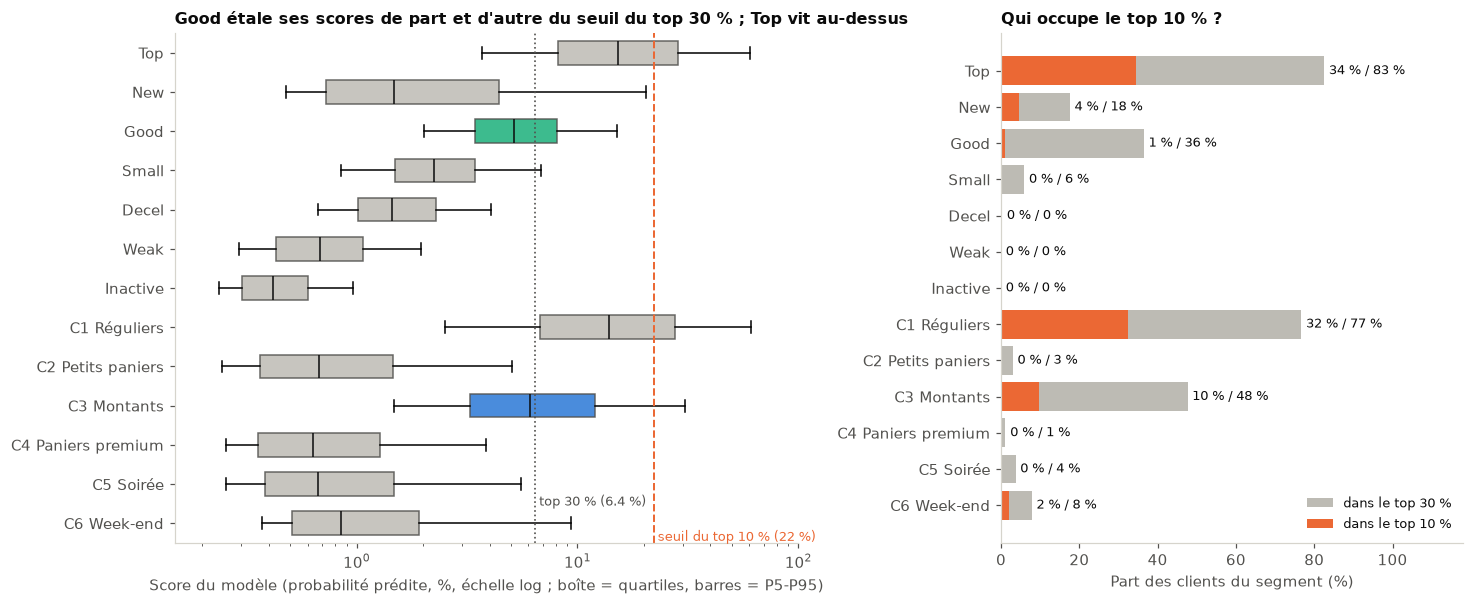

In [9]:
# distribution des scores par segment candidat + part dans le top 10 % / 30 %
thr10 = score.sort_values(ascending=False).iloc[K10 - 1]; thr30 = score.sort_values(ascending=False).iloc[int(0.3 * N) - 1]
order_seg = ['Top', 'New', 'Good', 'Small', 'Decel', 'Weak', 'Inactive']
order_cl = [n for n in T2.index if n.startswith('C')]
order_all = order_seg + order_cl
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={'width_ratios': [1.35, 1]})
ax = axes[0]
data = [score[cands[n][0].values].values * 100 for n in order_all][::-1]
bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
cl_col = {n: (c.GREEN if n == 'Good' else c.BLUE if n.startswith('C3') else c.GREY) for n in order_all}
for patch, n in zip(bp['boxes'], order_all[::-1]):
    patch.set_facecolor(cl_col[n]); patch.set_alpha(0.85); patch.set_edgecolor(c.INK2)
for med in bp['medians']: med.set_color(c.INK)
ax.set_yticks(range(1, len(order_all) + 1)); ax.set_yticklabels(order_all[::-1])
ax.set_xscale('log'); ax.set_xlim(0.15, 100)
ax.axvline(thr10 * 100, color=c.ACCENT, ls='--', lw=1.3); ax.text(thr10 * 100 * 1.04, 0.55, f"seuil du top 10 % ({thr10*100:.0f} %)", color=c.ACCENT, fontsize=8.5)
ax.axvline(thr30 * 100, color=c.INK2, ls=':', lw=1.1); ax.text(thr30 * 100 * 1.04, 1.45, f"top 30 % ({thr30*100:.1f} %)", color=c.INK2, fontsize=8.5)
ax.set_xlabel('Score du modèle (probabilité prédite, %, échelle log ; boîte = quartiles, barres = P5-P95)')
ax.set_title('Good étale ses scores de part et d\'autre du seuil du top 30 % ; Top vit au-dessus', fontsize=10.5, loc='left')
ax = axes[1]
p10 = T2.loc[order_all, 'part_top10'].values; p30 = T2.loc[order_all, 'part_top30'].values
yy = np.arange(len(order_all))[::-1]
ax.barh(yy, p30, color=c.GREY, label='dans le top 30 %'); ax.barh(yy, p10, color=c.ACCENT, label='dans le top 10 %')
for yi, a_, b_ in zip(yy, p10, p30): ax.text(b_ + 1.2, yi, f"{a_:.0f} % / {b_:.0f} %", va='center', fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(order_all); ax.set_xlim(0, 118); ax.set_xlabel('Part des clients du segment (%)')
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax.set_title('Qui occupe le top 10 % ?', fontsize=10.5, loc='left')
fig.tight_layout(); savefig(fig, '07_segments_scores')

In [10]:
# composition du top 10 % par segment RFM (budget de 10 %) et rachat dans chaque tranche de score à l'intérieur de Good
top_mask = rank <= K10
comp = pd.DataFrame({'Clients dans le top 10 %': seg[top_mask].value_counts(), 'Précision % (rachat)': y[top_mask].groupby(seg[top_mask]).mean() * 100}).reindex(order_seg).fillna(0)
comp['Part du top 10 %'] = 100 * comp['Clients dans le top 10 %'] / K10
show(comp[['Clients dans le top 10 %', 'Part du top 10 %', 'Précision % (rachat)']], precision=1)

# recouvrement de C3 Montants avec les segments RFM
c3n = [n for n in cl_tr_n.unique() if n.startswith('C3')][0]
ovl = pd.crosstab(cl_tr_n == c3n, seg, normalize='index').loc[True].reindex(order_seg) * 100
ov2 = pd.crosstab(seg, cl_tr_n == c3n, normalize='index')[True].reindex(order_seg) * 100
show(pd.DataFrame({'Composition de C3 Montants (% par segment RFM)': ovl, 'Part de chaque segment RFM classée en C3 (%)': ov2}), precision=1)
# Good : rachat par tranche de score intra-segment
g = (seg == 'Good').values
rk_g = score[g].rank(pct=True)
tier = pd.cut(rk_g, [0, 0.5, 0.8, 1.0], labels=['C : 50 % bas du score', 'B : 30 % suivants', 'A : 20 % haut du score'])
tab_g = pd.DataFrame({'clients': tier.value_counts(), 'rachat %': 100 * y[g].groupby(tier).mean(), 'score moyen %': 100 * score[g].groupby(tier).mean(),
                      'dont e-mailables': email[g].groupby(tier).sum(), 'dans le top 10 % global': top_mask[g].groupby(tier).sum()}).loc[['A : 20 % haut du score', 'B : 30 % suivants', 'C : 50 % bas du score']]
show(tab_g, precision=1)

,Clients dans le top 10 %,Part du top 10 %,Précision % (rachat)
rfm_segment,,,
Top,15 348,"95,7","41,2"
New,446,"2,8","31,8"
Good,238,"1,5","25,2"
Small,10,"0,1","0,0"
Decel,0,"0,0","0,0"
Weak,0,"0,0","0,0"
Inactive,0,"0,0","0,0"


,Composition de C3 Montants (% par segment RFM),Part de chaque segment RFM classée en C3 (%)
rfm_segment,,
Top,"46,5","33,3"
New,"12,6","40,4"
Good,"22,7","30,0"
Small,"15,4","43,9"
Decel,"1,4","3,5"
Weak,"1,2","2,3"
Inactive,"0,0","0,0"


,clients,rachat %,score moyen %,dont e-mailables,dans le top 10 % global
score,,,,,
A : 20 % haut du score,4 841,"13,4","13,5",3 044,238
B : 30 % suivants,7 261,"6,9","6,8",4 315,0
C : 50 % bas du score,12 101,"3,6","3,4",6 605,0


### Lecture et décision : confirmer, nuancer, ou changer ?

In [11]:
gd, c3, tp, nw = T2.loc['Good'], T2.loc[[n for n in T2.index if n.startswith('C3')][0]], T2.loc['Top'], T2.loc['New']
C3N = [n for n in T2.index if n.startswith('C3')][0]
top_in_top10 = comp.loc['Top', 'Part du top 10 %']
say(f"""**Ce que montre le croisement (🟦 mesuré)**
- **Le top 10 % par score est un top 10 % de clients « Top »** : {pc(top_in_top10, 0)} de ses {fr(K10)} places sont occupées par le segment Top ; Good n'y a que {fr(comp.loc['Good','Clients dans le top 10 %'])} clients ({pc(comp.loc['Good','Part du top 10 %'])}).
  Ces clients rachètent à {pc(comp.loc['Top','Précision % (rachat)'])} : c'est le meilleur *rendement en rachats*, mais c'est aussi la clientèle la plus régulière (le Top achète en moyenne tous les {Xtr.loc[seg=='Top','interval_mean_days'].median():.0f} jours environ) : la question « que change l'e-mail ? » y est la plus ouverte.
- **Good tient entre les deux** : taux de rachat {pc(gd['rachat'])} (lift {gd['rachat']/100/base:.2f} : *en dessous* de la moyenne), mais **{pc(gd['part_top30'], 0)} de ses clients sont dans le top 30 %** et ses scores s'étalent de {gd['score_médian']:.1f} % (médiane) à {gd['score_p90']:.0f} % (P90) :
  **le score sait trier à l'intérieur de Good** (AUC intra-segment {gd['auc_intra']:.3f}, contre {tp['auc_intra']:.3f} dans Top). Les 20 % de Good au meilleur score rachètent à {pc(tab_g.loc['A : 20 % haut du score','rachat %'])}, les 50 % les plus bas à {pc(tab_g.loc['C : 50 % bas du score','rachat %'])} :
  un ciblage *dans* Good isole une sous-population {tab_g.loc['A : 20 % haut du score','rachat %']/tab_g.loc['C : 50 % bas du score','rachat %']:.1f} fois plus encline à racheter que sa moitié basse.
- **Good est le plus gros segment ni très actif ni inactif** : {fr(gd['n_base_complète'])} clients ({fr(gd['n_email_complète'])} e-mailables, soit {pc(100*gd['n_email_complète']/K10_FULL, 0)} du budget de 10 %), {pc(gd['pct_rachats'])} des rachats.
  Il tient **à lui seul dans l'enveloppe de 10 %** de la base.
- **C3 Montants** ({fr(c3['n_base_complète'])} clients, rachat {pc(c3['rachat'])}, AUC intra {c3['auc_intra']:.3f}) : bon second, mais il **recoupe les segments RFM** : {pc(ovl['Top'],0)} de ses clients sont aussi dans Top et {pc(ovl['Good'],0)} dans Good ; sa part dans le top 10 % ({pc(c3['part_top10'],0)}) vient surtout de ses clients Top. C'est un portrait de comportement (hausse de fréquence) plus qu'un segment d'action, et il se prête moins à une offre unique.
- **New** : AUC intra-segment le plus élevé ({nw['auc_intra']:.3f}) mais effectif et valeur faibles ; l'historique de 12 mois ne permet pas de distinguer les vrais nouveaux des clients occasionnels.

**Verdict** : **on confirme Good comme segment pour l'oral, avec trois nuances honnêtes.**
1. **Ce n'est pas le segment qui capte le plus de rachats, ni celui qui porte le plus de marge brute.** À uplift identique (+1 point 🟧), la marge brute provoquée est de {fr(tp['brute_abs_k€'],1)} k€ pour Top ({fr(tp['n_email_complète'])} e-mailables) contre {fr(gd['brute_abs_k€'],1)} k€ pour Good ({fr(gd['n_email_complète'])}) : Top gagne au volume ; sous un uplift proportionnel (+10 % 🟧) l'écart se creuse ({fr(tp['brute_rel_k€'],1)} contre {fr(gd['brute_rel_k€'],1)} k€). 
   Mais **Top coûte plus cher à convaincre** : il faut {tp['seuil_abs_pts']:.1f} points d'uplift pour couvrir la remise et l'envoi, contre {gd['seuil_abs_pts']:.1f} pour Good, parce que la remise est distribuée à des clients qui auraient acheté de toute façon ({pc(tp['rachat_email'])} de rachat de base contre {pc(gd['rachat_email'])}). 
   **Les données ne permettent pas de dire lequel des deux réagit le plus à un e-mail : seul un test A/B le fera** (section 5). Good est un pari « incrémental » *par hypothèse* (clients moins saturés), Top un pari « volume ».
2. **Le segment doit être travaillé avec le score** : cibler *tout* Good sans trier revient à payer des e-mails et des remises pour les {pc(tab_g.loc['C : 50 % bas du score','rachat %'])} de rachat de sa moitié basse.
3. **Le top 10 % global et le segment Good sont deux usages différents** du score : le premier alimente la campagne de masse (surtout des clients Top), le second est le levier de croissance étudié ci-dessous.
""")

**Ce que montre le croisement (🟦 mesuré)**
- **Le top 10 % par score est un top 10 % de clients « Top »** : 96 % de ses 16 042 places sont occupées par le segment Top ; Good n'y a que 238 clients (1,5 %).
  Ces clients rachètent à 41,2 % : c'est le meilleur *rendement en rachats*, mais c'est aussi la clientèle la plus régulière (le Top achète en moyenne tous les 9 jours environ) : la question « que change l'e-mail ? » y est la plus ouverte.
- **Good tient entre les deux** : taux de rachat 6,5 % (lift 0,85 : *en dessous* de la moyenne), mais **36 % de ses clients sont dans le top 30 %** et ses scores s'étalent de 5,2 % (médiane) à 12 % (P90) :
  **le score sait trier à l'intérieur de Good** (AUC intra-segment 0,677, contre 0,779 dans Top). Les 20 % de Good au meilleur score rachètent à 13,4 %, les 50 % les plus bas à 3,6 % :
  un ciblage *dans* Good isole une sous-population 3,7 fois plus encline à racheter que sa moitié basse.
- **Good est le plus gros segment ni très actif ni inactif** : 30 307 clients (17 486 e-mailables, soit 87 % du budget de 10 %), 12,8 % des rachats.
  Il tient **à lui seul dans l'enveloppe de 10 %** de la base.
- **C3 Montants** (39 927 clients, rachat 9,8 %, AUC intra 0,770) : bon second, mais il **recoupe les segments RFM** : 47 % de ses clients sont aussi dans Top et 23 % dans Good ; sa part dans le top 10 % (10 %) vient surtout de ses clients Top. C'est un portrait de comportement (hausse de fréquence) plus qu'un segment d'action, et il se prête moins à une offre unique.
- **New** : AUC intra-segment le plus élevé (0,846) mais effectif et valeur faibles ; l'historique de 12 mois ne permet pas de distinguer les vrais nouveaux des clients occasionnels.

**Verdict** : **on confirme Good comme segment pour l'oral, avec trois nuances honnêtes.**
1. **Ce n'est pas le segment qui capte le plus de rachats, ni celui qui porte le plus de marge brute.** À uplift identique (+1 point 🟧), la marge brute provoquée est de 4,8 k€ pour Top (33 837 e-mailables) contre 2,4 k€ pour Good (17 486) : Top gagne au volume ; sous un uplift proportionnel (+10 % 🟧) l'écart se creuse (10,6 contre 1,7 k€). 
   Mais **Top coûte plus cher à convaincre** : il faut 3,1 points d'uplift pour couvrir la remise et l'envoi, contre 1,1 pour Good, parce que la remise est distribuée à des clients qui auraient acheté de toute façon (21,9 % de rachat de base contre 7,0 %). 
   **Les données ne permettent pas de dire lequel des deux réagit le plus à un e-mail : seul un test A/B le fera** (section 5). Good est un pari « incrémental » *par hypothèse* (clients moins saturés), Top un pari « volume ».
2. **Le segment doit être travaillé avec le score** : cibler *tout* Good sans trier revient à payer des e-mails et des remises pour les 3,6 % de rachat de sa moitié basse.
3. **Le top 10 % global et le segment Good sont deux usages différents** du score : le premier alimente la campagne de masse (surtout des clients Top), le second est le levier de croissance étudié ci-dessous.


## 3. Le segment retenu : Good, persona, leviers, message, canal, calendrier

**Définition** (notebook 05, seuils métier) : clients ni *Inactive* (achat dans les 180 jours) ni *New* (≥ 90 jours d'ancienneté), de **fréquence et montant moyens ou élevés** mais de **récence moyenne** (dernier achat il y a 15 à 60 jours). Ce sont des clients qui ont l'habitude de venir mais qui « ralentissent » ou « patientent » : l'e-mail intervient pendant qu'ils hésitent.

On décrit d'abord *qui ils sont*, puis *ce qui sépare ceux qui rachètent de ceux qui ne rachètent pas* à l'intérieur de Good (🟦 mesuré, descriptif : ce sont des associations, pas des causes).

In [12]:
gm = (seg == 'Good').values
yg = y[gm]; Xg = Xtr[gm]
civ = Xtr['civility'].astype(str)
def prof(mask):
    X_ = Xtr[mask]
    return {'Récence : jours depuis le dernier achat (médiane)': X_['recency_days'].median(),
            'Tickets sur 12 mois (médiane)': X_['n_tickets_all'].median(),
            'Mois actifs sur 12 (moyenne)': X_['n_active_months'].mean(),
            'Intervalle moyen entre deux achats, jours (médiane)': X_['interval_mean_days'].median(),
            'Dépense annuelle, € (médiane)': X_['spend_all'].median(),
            'Panier moyen, € (médiane)': X_['basket_mean_all'].median(),
            'Part des tickets le week-end % (moyenne)': 100 * X_['share_weekend'].mean(),
            'Part des tickets en soirée % (moyenne)': 100 * X_['share_evening'].mean(),
            'Taux de remise moyen % (moyenne)': 100 * X_['discount_rate_all'].clip(lower=0).mean(),
            'Part de tickets avec remise % (moyenne)': 100 * X_['share_tickets_disc'].mean(),
            'Magasins fréquentés (médiane)': X_['n_stores'].median(),
            '% joignables par e-mail': 100 * X_['has_email'].astype(bool).mean(),
            '% avec carte de fidélité': 100 * X_['has_card'].astype(bool).mean(),
            '% Mme (civilité renseignée)': 100 * (civ[mask] == 'MME').sum() / max((civ[mask].isin(['M', 'MME'])).sum(), 1),
            'Rachat en août 2020 %': 100 * y[mask].mean()}
persona = pd.DataFrame({'Good : racheteurs': prof(gm & (y == 1).values), 'Good : non-racheteurs': prof(gm & (y == 0).values),
                        'Good (ensemble)': prof(gm), 'Base complète': prof(np.ones(N, bool)), 'Top': prof((seg == 'Top').values)})
show(persona.round(1), precision=1)

,Good : racheteurs,Good : non-racheteurs,Good (ensemble),Base complète,Top
Récence : jours depuis le dernier achat (médiane),"24,0","29,0","29,0","45,0","4,0"
Tickets sur 12 mois (médiane),"23,0","17,0","17,0","8,0","36,0"
Mois actifs sur 12 (moyenne),"9,0","8,1","8,1","5,5","9,9"
"Intervalle moyen entre deux achats, jours (médiane)","13,6","17,9","17,6","15,6","9,0"
"Dépense annuelle, € (médiane)","978,9","718,5","732,3","330,3","1 591,8"
"Panier moyen, € (médiane)","44,4","43,0","43,1","39,4","45,1"
Part des tickets le week-end % (moyenne),"32,0","25,8","26,3","25,9","26,2"
Part des tickets en soirée % (moyenne),"20,4","19,5","19,6","20,2","18,5"
Taux de remise moyen % (moyenne),"4,3","4,1","4,1","4,2","5,1"
Part de tickets avec remise % (moyenne),"36,4","35,6","35,6","34,8","39,4"


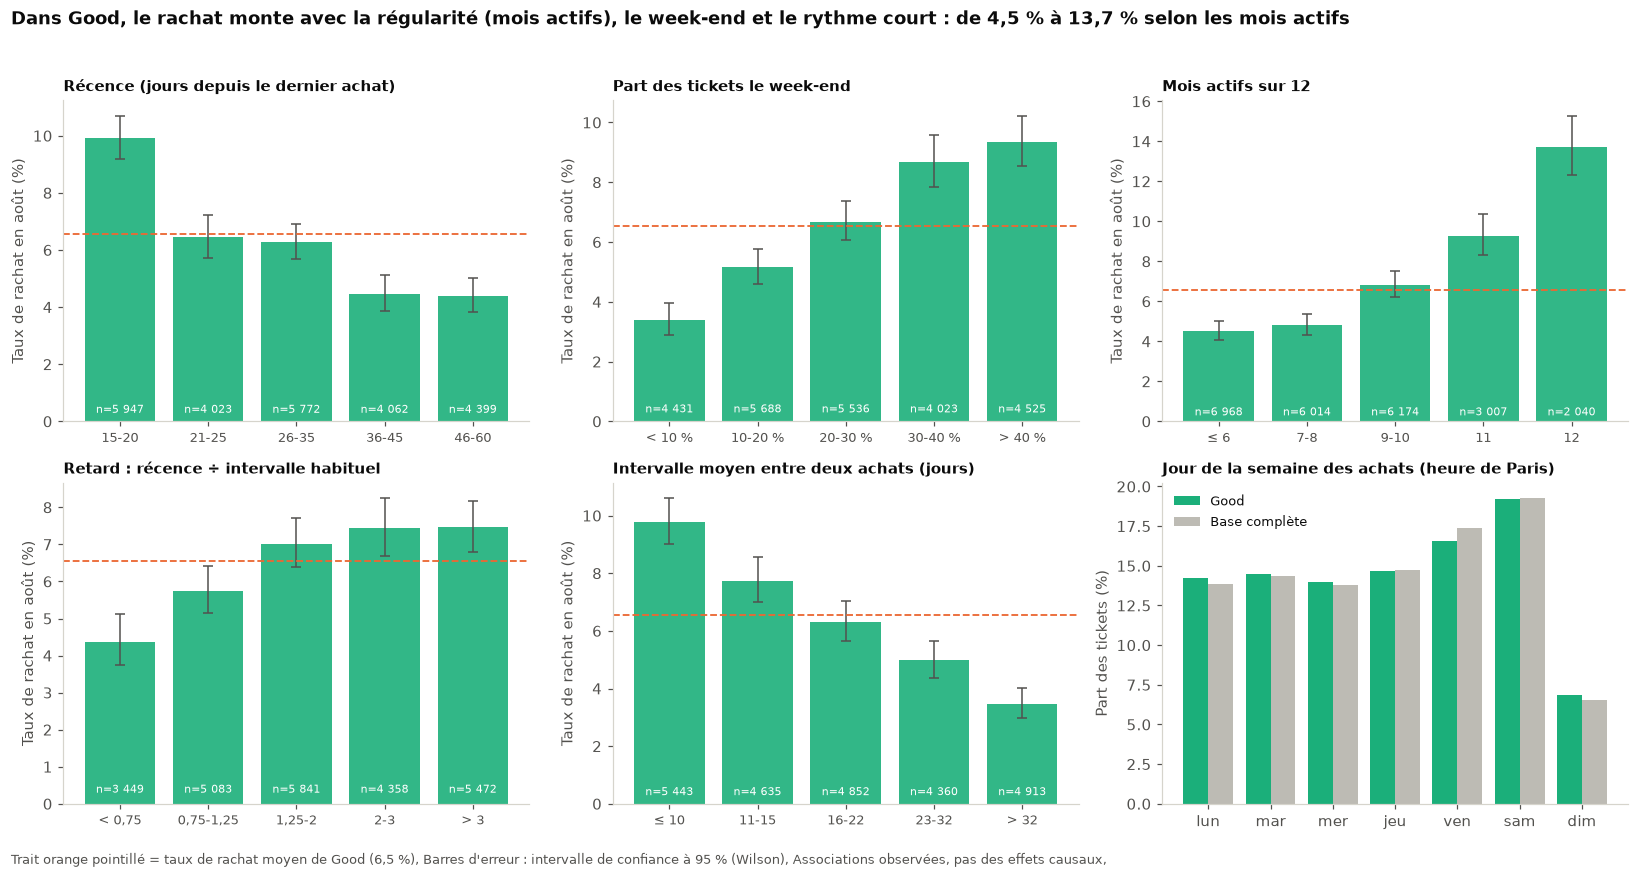

Récence (jours depuis le dernier achat) -> [9.9, 6.4, 6.3, 4.5, 4.4]
Part des tickets le week-end -> [3.4, 5.2, 6.7, 8.7, 9.3]
Mois actifs sur 12 -> [4.5, 4.8, 6.8, 9.3, 13.7]
Retard : récence ÷ intervalle habituel -> [4.4, 5.7, 7.0, 7.4, 7.5]
Intervalle moyen entre deux achats (jours) -> [9.8, 7.7, 6.3, 5.0, 3.5]
Part des tickets Good par jour (lun-dim) : [14.2, 14.5, 14.0, 14.7, 16.6, 19.2, 6.8] | base : [13.9, 14.4, 13.8, 14.8, 17.4, 19.3, 6.6]
Heures (Paris) les plus fréquentes : {12: 12.0, 13: 11.5, 19: 10.0, 18: 9.9, 11: 8.7}


In [13]:
# leviers : rachat à l'intérieur de Good selon récence, part de week-end, régularité et rythme (🟦 mesuré, descriptif)
ratio = (Xg['recency_days'] / Xg['interval_mean_days'].clip(lower=1)).replace([np.inf], np.nan)
def rate_by(x, bins, labels=None):
    cat = pd.cut(x, bins, labels=labels, include_lowest=True)
    out = pd.DataFrame({'n': yg.groupby(cat).size(), 'rate': 100 * yg.groupby(cat).mean()})
    out['lo'], out['hi'] = zip(*[(100 * v[0], 100 * v[1]) for v in [proportion_confint(int(round(r_ / 100 * n_)), n_, method='wilson') if n_ > 0 else (0, 0) for r_, n_ in zip(out['rate'], out['n'])]])
    return out
lev = {
    'Récence (jours depuis le dernier achat)': rate_by(Xg['recency_days'], [14, 20, 25, 35, 45, 60], ['15-20', '21-25', '26-35', '36-45', '46-60']),
    'Part des tickets le week-end': rate_by(Xg['share_weekend'], [-0.01, 0.1, 0.2, 0.3, 0.4, 1.0], ['< 10 %', '10-20 %', '20-30 %', '30-40 %', '> 40 %']),
    'Mois actifs sur 12': rate_by(Xg['n_active_months'], [0, 6, 8, 10, 11, 12], ['≤ 6', '7-8', '9-10', '11', '12']),
    "Retard : récence ÷ intervalle habituel": rate_by(ratio, [0, 0.75, 1.25, 2, 3, 100], ['< 0,75', '0,75-1,25', '1,25-2', '2-3', '> 3']),
    'Intervalle moyen entre deux achats (jours)': rate_by(Xg['interval_mean_days'], [0, 10, 15, 22, 32, 200], ['≤ 10', '11-15', '16-22', '23-32', '> 32']),
}
# jour de la semaine et heure des tickets des clients Good (12 mois d'historique)
tk = c.load_clean('train')[0]
tk = tk[tk['id_client'].isin(Xg.index) & ~tk['is_return']].copy()
tk['loc'] = tk['ts'].dt.tz_localize('UTC').dt.tz_convert('Europe/Paris')
wd = tk['loc'].dt.dayofweek.value_counts(normalize=True).sort_index() * 100
tk_all = c.load_clean('train')[0]; tk_all = tk_all[~tk_all['is_return']]
wd_all = tk_all['ts'].dt.tz_localize('UTC').dt.tz_convert('Europe/Paris').dt.dayofweek.value_counts(normalize=True).sort_index() * 100
hr = tk['loc'].dt.hour.value_counts(normalize=True).sort_index() * 100
del tk_all

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
avg = 100 * yg.mean()
for ax, (ttl, d_) in zip(axes.ravel()[:5], lev.items()):
    ax.bar(range(len(d_)), d_['rate'], color=[c.GREEN] * len(d_), alpha=0.9, yerr=[d_['rate'] - d_['lo'], d_['hi'] - d_['rate']], error_kw=dict(ecolor=c.INK2, lw=1, capsize=3))
    ax.axhline(avg, color=c.ACCENT, ls='--', lw=1.2)
    ax.set_xticks(range(len(d_))); ax.set_xticklabels(d_.index, fontsize=8.5); ax.set_title(ttl, fontsize=10, loc='left'); ax.set_ylabel('Taux de rachat en août (%)')
    for i_, (r_, n_) in enumerate(zip(d_['rate'], d_['n'])): ax.text(i_, 0.3, f"n={fr(n_)}", ha='center', fontsize=7.5, color='white')
ax = axes.ravel()[5]
days = ['lun', 'mar', 'mer', 'jeu', 'ven', 'sam', 'dim']
xx = np.arange(7); ax.bar(xx - 0.2, wd.values, 0.4, color=c.GREEN, label='Good'); ax.bar(xx + 0.2, wd_all.values, 0.4, color=c.GREY, label='Base complète')
ax.set_xticks(xx); ax.set_xticklabels(days); ax.set_ylabel('Part des tickets (%)'); ax.legend(frameon=False, fontsize=8.5)
ax.set_title('Jour de la semaine des achats (heure de Paris)', fontsize=10, loc='left')
fig.suptitle(f"Dans Good, le rachat monte avec la régularité (mois actifs), le week-end et le rythme court : de {lev['Mois actifs sur 12']['rate'].min():.1f} % à {lev['Mois actifs sur 12']['rate'].max():.1f} % selon les mois actifs".replace('.', ','), x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.tight_layout(rect=(0, 0.03, 1, 0.96)); fig.text(0.01, 0.01, f"Trait orange pointillé = taux de rachat moyen de Good ({avg:.1f} %). Barres d'erreur : intervalle de confiance à 95 % (Wilson). Associations observées, pas des effets causaux.".replace('.', ','), fontsize=8.5, color=c.INK2)
savefig(fig, '07_good_leviers')
for k_, v_ in lev.items(): print(k_, '->', v_['rate'].round(1).tolist())
print('Part des tickets Good par jour (lun-dim) :', wd.round(1).tolist(), '| base :', wd_all.round(1).tolist())
print('Heures (Paris) les plus fréquentes :', hr.sort_values(ascending=False).head(5).round(1).to_dict())

In [14]:
# tranches de score à l'intérieur de Good : effectifs « base complète » (e-mailables), pour dimensionner la campagne
tier_g = tier.astype(str).str[0]                              # A, B, C
share_t = pd.Series({t: (tier_g[email[gm]] == t).sum() for t in 'ABC'}) / email[gm].sum()
n_good_email_full = int(T2.loc['Good', 'n_email_complète'])
tiers = pd.DataFrame({'clients (train)': tier_g.value_counts().sort_index(),
                      'e-mailables (train)': pd.Series({t: int((tier_g[email[gm]] == t).sum()) for t in 'ABC'}),
                      'rachat % (🟦, e-mailables)': pd.Series({t: 100 * y[gm][email[gm] & (tier_g == t)].mean() for t in 'ABC'}),
                      'panier moyen € (🟦, e-mailables)': pd.Series({t: basket[gm][email[gm] & (tier_g == t)].mean() for t in 'ABC'})})
tiers['e-mailables (base complète)'] = (share_t * n_good_email_full).round().astype(int)
tiers['rachats attendus (base complète)'] = tiers['e-mailables (base complète)'] * tiers['rachat % (🟦, e-mailables)'] / 100
tiers.index = ['A : 20 % haut du score', 'B : 30 % suivants', 'C : 50 % bas du score']
show(tiers, precision=1)

,clients (train),e-mailables (train),"rachat % (🟦, e-mailables)","panier moyen € (🟦, e-mailables)",e-mailables (base complète),rachats attendus (base complète)
A : 20 % haut du score,4 841,3 044,"13,8","58,1",3 812,"526,0"
B : 30 % suivants,7 261,4 315,"6,9","54,5",5 403,"370,6"
C : 50 % bas du score,12 101,6 605,"3,9","54,9",8 271,"320,6"


### Recommandations pour Good

*(Les chiffres entre parenthèses sont ceux calculés ci-dessus ; les propositions de contenu et de calendrier sont des **recommandations**, pas des résultats mesurés.)*

In [15]:
rec_w = lev['Part des tickets le week-end']['rate']; rec_m = lev['Mois actifs sur 12']['rate']; rec_r = lev['Récence (jours depuis le dernier achat)']['rate']
rec_d = lev['Retard : récence ÷ intervalle habituel']['rate']
d_sens = 100 * yg.groupby(pd.qcut(Xg['share_tickets_disc'], 5, duplicates='drop')).mean()
wk = wd[[4, 5]].sum()   # vendredi + samedi
say(f"""**Persona** *(synthèse chiffrée de la table ci-dessus)* : la **cliente ou le client « habitué qui ralentit »**. Il vient **{persona.loc['Tickets sur 12 mois (médiane)','Good (ensemble)']:.0f} fois par an** (contre {persona.loc['Tickets sur 12 mois (médiane)','Top']:.0f} pour le Top),
sur {persona.loc['Mois actifs sur 12 (moyenne)','Good (ensemble)']:.1f} mois sur 12 en moyenne, avec un panier médian de {persona.loc['Panier moyen, € (médiane)','Good (ensemble)']:.0f} € (base complète : {persona.loc['Panier moyen, € (médiane)','Base complète']:.0f} € : **c'est la fréquence qui le distingue, pas le panier**).
Il n'est pas venu depuis {persona.loc['Récence : jours depuis le dernier achat (médiane)','Good (ensemble)']:.0f} jours (médiane) alors que son intervalle habituel est de {persona.loc['Intervalle moyen entre deux achats, jours (médiane)','Good (ensemble)']:.0f} jours.
{pc(persona.loc['% joignables par e-mail','Good (ensemble)'], 0)} sont joignables par e-mail, {pc(persona.loc['% avec carte de fidélité','Good (ensemble)'], 0)} ont une carte de fidélité (peu : la carte n'est pas un levier de ciblage ici).
Les racheteurs de Good ressemblent à des « presque Top » : plus de mois actifs ({persona.loc['Mois actifs sur 12 (moyenne)','Good : racheteurs']:.1f} contre {persona.loc['Mois actifs sur 12 (moyenne)','Good : non-racheteurs']:.1f}), plus de week-end ({pc(persona.loc['Part des tickets le week-end % (moyenne)','Good : racheteurs'],0)} contre {pc(persona.loc['Part des tickets le week-end % (moyenne)','Good : non-racheteurs'],0)}).

**Leviers** (rachat en août à l'intérieur de Good, 🟦 associations observées)
1. **Régularité d'abord** : de {rec_m.min():.1f} % (≤ 6 mois actifs) à {rec_m.max():.1f} % (12 mois actifs). Ce sont les « réguliers qui s'éloignent », à relancer en priorité, pas les occasionnels.
2. **Timing selon la récence** : le rachat « naturel » recule quand le dernier achat s'éloigne ({rec_r.iloc[0]:.1f} % à 15-20 jours, {rec_r.iloc[-1]:.1f} % à 46-60 jours). Passé 60 jours, le client bascule vers Decel (rachat {pc(T2.loc['Decel','rachat'])}) : **le bon moment pour le relancer est avant ce basculement**, plutôt que d'attendre qu'il s'éloigne.
3. **Timing selon le rythme d'achat** : les clients dont l'intervalle habituel est court (≤ 10 jours) rachètent à {lev['Intervalle moyen entre deux achats (jours)']['rate'].iloc[0]:.1f} %, ceux dont il dépasse 32 jours à {lev['Intervalle moyen entre deux achats (jours)']['rate'].iloc[-1]:.1f} %. 
   Le *retard* (récence ÷ intervalle habituel) est associé à un rachat plus élevé ({rec_d.iloc[0]:.1f} % si < 0,75 ; {rec_d.iloc[-1]:.1f} % si > 3) : c'est surtout un effet de fréquence (un client à intervalle court qui n'est pas venu depuis 15 jours est déjà « en retard »). 
   **Recommandation** : déclencher l'e-mail quand la récence dépasse l'intervalle habituel du client (message « personnalisé au rythme »), plutôt que sur un calendrier unique ; à valider dans le test.
4. **Week-end** : la part de tickets le week-end passe de {rec_w.iloc[0]:.1f} % de rachat (< 10 %) à {rec_w.iloc[-1]:.1f} % (> 40 %). Vendredi et samedi concentrent {pc(wk, 0)} des tickets de Good : **envoyer le jeudi soir ou le vendredi matin, offre valable le week-end**.
   ⚠ août 2020 commence un samedi et contient 10 jours de week-end : l'effet peut être en partie du calendrier (un seul mois cible, non testable).
5. **Remise** : {pc(persona.loc['Part de tickets avec remise % (moyenne)','Good (ensemble)'],0)} des tickets de Good portent déjà une remise (taux moyen {pc(persona.loc['Taux de remise moyen % (moyenne)','Good (ensemble)'])}) et le rachat varie peu avec la sensibilité aux promotions passées ({d_sens.min():.1f} % à {d_sens.max():.1f} % selon les quintiles de part de tickets remisés) :
   **la remise n'est pas le levier discriminant ; testons une remise modeste et un message sans remise** (section 5).

**Message** *(proposition)* : ton « on a pensé à vous pour votre prochain panier du week-end » plutôt que « grosse promo » ; objet du type *« Votre panier du week-end : −10 % jusqu'à dimanche »*, rappel de la routine du client (magasin habituel, produits habituels si l'enseigne a ces données), offre simple, valable 7 jours, avec date limite visible. Une variante sans remise (« rappel + service ») sert de comparaison.

**Canal** : **e-mail** pour les {fr(n_good_email_full)} e-mailables de Good ({pc(100*n_good_email_full/T2.loc['Good','n_base_complète'],0)} du segment) ; les autres (hors e-mail) demandent un autre canal (courrier, notification, coupon en caisse) **pour lequel nous n'avons pas de données** : à tester séparément, non chiffré ici.

**Calendrier** *(en jours à partir de l'envoi J0 ; le jour exact dépend du lancement de la campagne)*
- **J − 14** : scoring, tirage au sort du groupe témoin, validation du contenu et du consentement RGPD. **J − 7** : création de l'e-mail, plan de suivi.
- **J0 : jeudi ou vendredi matin** (avant le week-end), envoi aux traités (tirés au sort). **J + 3** : relance des non-ouvreurs avec un autre objet. **J + 7** : fin de validité de l'offre.
- **J + 30** : fin de la fenêtre d'observation (même définition que la cible : achat dans le mois) ; **J + 60** : contrôle de l'effet « achat avancé » (les clients ont-ils simplement acheté plus tôt ?).
""")

**Persona** *(synthèse chiffrée de la table ci-dessus)* : la **cliente ou le client « habitué qui ralentit »**. Il vient **17 fois par an** (contre 36 pour le Top),
sur 8,1 mois sur 12 en moyenne, avec un panier médian de 43 € (base complète : 39 € : **c'est la fréquence qui le distingue, pas le panier**).
Il n'est pas venu depuis 29 jours (médiane) alors que son intervalle habituel est de 18 jours.
58 % sont joignables par e-mail, 3 % ont une carte de fidélité (peu : la carte n'est pas un levier de ciblage ici).
Les racheteurs de Good ressemblent à des « presque Top » : plus de mois actifs (9,0 contre 8,1), plus de week-end (32 % contre 26 %).

**Leviers** (rachat en août à l'intérieur de Good, 🟦 associations observées)
1. **Régularité d'abord** : de 4,5 % (≤ 6 mois actifs) à 13,7 % (12 mois actifs). Ce sont les « réguliers qui s'éloignent », à relancer en priorité, pas les occasionnels.
2. **Timing selon la récence** : le rachat « naturel » recule quand le dernier achat s'éloigne (9,9 % à 15-20 jours, 4,4 % à 46-60 jours). Passé 60 jours, le client bascule vers Decel (rachat 1,8 %) : **le bon moment pour le relancer est avant ce basculement**, plutôt que d'attendre qu'il s'éloigne.
3. **Timing selon le rythme d'achat** : les clients dont l'intervalle habituel est court (≤ 10 jours) rachètent à 9,8 %, ceux dont il dépasse 32 jours à 3,5 %. 
   Le *retard* (récence ÷ intervalle habituel) est associé à un rachat plus élevé (4,4 % si < 0,75 ; 7,5 % si > 3) : c'est surtout un effet de fréquence (un client à intervalle court qui n'est pas venu depuis 15 jours est déjà « en retard »). 
   **Recommandation** : déclencher l'e-mail quand la récence dépasse l'intervalle habituel du client (message « personnalisé au rythme »), plutôt que sur un calendrier unique ; à valider dans le test.
4. **Week-end** : la part de tickets le week-end passe de 3,4 % de rachat (< 10 %) à 9,3 % (> 40 %). Vendredi et samedi concentrent 36 % des tickets de Good : **envoyer le jeudi soir ou le vendredi matin, offre valable le week-end**.
   ⚠ août 2020 commence un samedi et contient 10 jours de week-end : l'effet peut être en partie du calendrier (un seul mois cible, non testable).
5. **Remise** : 36 % des tickets de Good portent déjà une remise (taux moyen 4,1 %) et le rachat varie peu avec la sensibilité aux promotions passées (6,1 % à 6,9 % selon les quintiles de part de tickets remisés) :
   **la remise n'est pas le levier discriminant ; testons une remise modeste et un message sans remise** (section 5).

**Message** *(proposition)* : ton « on a pensé à vous pour votre prochain panier du week-end » plutôt que « grosse promo » ; objet du type *« Votre panier du week-end : −10 % jusqu'à dimanche »*, rappel de la routine du client (magasin habituel, produits habituels si l'enseigne a ces données), offre simple, valable 7 jours, avec date limite visible. Une variante sans remise (« rappel + service ») sert de comparaison.

**Canal** : **e-mail** pour les 17 486 e-mailables de Good (58 % du segment) ; les autres (hors e-mail) demandent un autre canal (courrier, notification, coupon en caisse) **pour lequel nous n'avons pas de données** : à tester séparément, non chiffré ici.

**Calendrier** *(en jours à partir de l'envoi J0 ; le jour exact dépend du lancement de la campagne)*
- **J − 14** : scoring, tirage au sort du groupe témoin, validation du contenu et du consentement RGPD. **J − 7** : création de l'e-mail, plan de suivi.
- **J0 : jeudi ou vendredi matin** (avant le week-end), envoi aux traités (tirés au sort). **J + 3** : relance des non-ouvreurs avec un autre objet. **J + 7** : fin de validité de l'offre.
- **J + 30** : fin de la fenêtre d'observation (même définition que la cible : achat dans le mois) ; **J + 60** : contrôle de l'effet « achat avancé » (les clients ont-ils simplement acheté plus tôt ?).


## 4. Scénarios économiques : ciblage par score, hasard ou segment entier ?

**Principe** : pour chaque stratégie, on mesure ce qui se mesure (taux de rachat de la population ciblée, panier moyen, effectifs), puis on **suppose** l'effet de l'e-mail (uplift) et les coûts. Marge nette par client contacté :

> marge nette = (rachats provoqués × panier × marge) − (remise × panier × part d'utilisation × tous les acheteurs, y compris ceux qui auraient acheté sans e-mail) − coût de contact

Deux manières de supposer l'uplift, parce que la réponse dépend de ce qu'on croit :
- **Uplift absolu** (+0,5 / +1 / +2 points de rachat pour tout client contacté) : le score ne dit rien sur qui est influençable. Le ciblage par score ne crée pas plus de rachats provoqués, il **coûte plus de remise** (les rachats de base sont plus nombreux dans une cible à forte propension).
- **Uplift relatif** (+5 / +10 / +20 % du taux de base) : ceux qui rachètent déjà beaucoup réagiraient proportionnellement plus. C'est l'hypothèse la plus **favorable au ciblage par score**, et la moins vérifiée (à +10 %, un client dont le taux de base est de 30 % gagnerait 3 points).

Toutes les stratégies sont comparées **parmi des clients joignables par e-mail** (sinon l'e-mail n'est pas envoyé). 🟦 mesuré : `p` et `b` ; 🟧 supposé : uplift, remise, marge, coût.

In [16]:
# --- stratégies (train pour les taux mesurés, base complète pour les volumes) -------------------------------------
def pick(s, mask, k):
    se = s[mask]; return se.index[np.argsort(-se.values, kind='stable')[:k]]
idx_all = pd.Series(True, index=Xtr.index)
good_em = (seg == 'Good') & email
strategies = {}
strategies['Top 10 % par score (e-mailables)'] = dict(idx=pick(score, email, K10), n_full=K10_FULL)
strategies['Top 10 % par récence (e-mailables)'] = dict(idx=pick(pred['Règle de récence'], email, K10), n_full=K10_FULL)
strategies['Top 10 % par score RFM (e-mailables)'] = dict(idx=pick(pred['Score RFM'], email, K10), n_full=K10_FULL)
strategies['10 % au hasard (e-mailables)'] = dict(idx=email[email].index, n_full=K10_FULL)
strategies['Good : tous les e-mailables'] = dict(idx=good_em[good_em].index, n_full=n_good_email_full)
n_AB_full = int((tiers.loc[['A : 20 % haut du score', 'B : 30 % suivants'], 'e-mailables (base complète)']).sum())
ge = good_em[good_em].index
keep = tier_g.reindex(ge).isin(['A', 'B'])
strategies['Good : e-mailables, 50 % haut du score'] = dict(idx=ge[keep.values], n_full=n_AB_full)
strategies['Good : e-mailables, 50 % au hasard'] = dict(idx=ge, n_full=n_AB_full)      # même taille que la ligne précédente, choisis au hasard
rows = []
for name, s_ in strategies.items():
    ix = s_['idx']
    p = y[ix].mean(); b = basket[ix].mean()
    lo, hi = proportion_confint(int(y[ix].sum()), len(ix), method='wilson')
    row = dict(stratégie=name, clients_contactés=s_['n_full'], p_rachat=100 * p, p_bas=100 * lo, p_haut=100 * hi, panier=b,
               rachats_de_base=s_['n_full'] * p)
    for mode, key in [('abs', 'uplift_abs'), ('rel', 'uplift_rel')]:
        for lvl in ['bas', 'central', 'haut']:
            r_ = net_per_contact(p, b, ASSUME[key][lvl], mode)
            row[f'net_{mode}_{lvl}'] = r_['net'] * s_['n_full']
            row[f'roi_{mode}_{lvl}'] = r_['net'] / r_['cost']
            row[f'inc_{mode}_{lvl}'] = r_['inc'] * s_['n_full']
            row[f'cout_{mode}_{lvl}'] = r_['cost'] * s_['n_full']
        row[f'seuil_uplift_{mode}'] = breakeven_uplift(p, b, mode)
        row[f'remise_max_{mode}'] = max_discount(p, b, ASSUME[key]['central'], mode)
    row['seuil_abs_d5'] = breakeven_uplift(p, b, 'abs', {**ASSUME, 'discount': 0.05})
    row['seuil_abs_d0'] = breakeven_uplift(p, b, 'abs', {**ASSUME, 'discount': 0.0})
    row['seuil_abs_r100'] = breakeven_uplift(p, b, 'abs', {**ASSUME, 'redeem': 1.0})
    rows.append(row)
T4 = pd.DataFrame(rows).set_index('stratégie')
tab = pd.DataFrame({'Contactés (base complète)': T4['clients_contactés'], 'Rachat % 🟦': T4['p_rachat'], 'Panier € 🟦': T4['panier'],
                    'Rachats de base 🟦': T4['rachats_de_base'],
                    'Seuil de rentabilité (pts) : remise 10 %': T4['seuil_abs_pts'] if 'seuil_abs_pts' in T4 else T4['seuil_uplift_abs'] * 100,
                    'remise 5 %': T4['seuil_abs_d5'] * 100, 'sans remise (rappel)': T4['seuil_abs_d0'] * 100, 'remise 10 %, utilisation 100 %': T4['seuil_abs_r100'] * 100,
                    'Seuil relatif % (remise 10 %)': T4['seuil_uplift_rel'] * 100})
display(Markdown("**Seuils de rentabilité** (uplift minimal en points de rachat pour une marge nette nulle ; 🟦 `p`, `b` mesurés, 🟧 le reste)"))
show(tab, precision=2)
net_tab = pd.DataFrame({f'{lab} {lvl}': T4[f'net_{m_}_{lvl}'] / 1000 for m_, lab in [('abs', 'Uplift absolu'), ('rel', 'Uplift relatif')] for lvl in ['bas', 'central', 'haut']})
net_tab.columns = [f"{a_} ({'/'.join(f'+{100*v:.1f}' for v in ASSUME['uplift_abs'].values())} pt) : {l_}" if 'absolu' in a_ else f"{a_} ({'/'.join(f'+{100*v:.0f}' for v in ASSUME['uplift_rel'].values())} %) : {l_}" for a_, l_ in [c_.rsplit(' ', 1) for c_ in net_tab.columns]]
display(Markdown("**Marge nette de la campagne (k€, base complète)** selon le scénario 🟧 d'uplift (remise 10 %)"))
show(net_tab, precision=1)
roi_tab = pd.DataFrame({'Coût total campagne k€ (envoi + remise), +1 pt': T4['cout_abs_central'] / 1000, 'ROI % : +1 pt': 100 * T4['roi_abs_central'], 'ROI % : +10 %': 100 * T4['roi_rel_central'],
                        'ROI % : +2 pts': 100 * T4['roi_abs_haut'], 'ROI % : +20 %': 100 * T4['roi_rel_haut'], 'Remise max % à +1 pt': 100 * T4['remise_max_abs']})
display(Markdown('**Coût et ROI** (ROI = marge nette ÷ coût total, en %)'))
show(roi_tab, precision=1)

**Seuils de rentabilité** (uplift minimal en points de rachat pour une marge nette nulle ; 🟦 `p`, `b` mesurés, 🟧 le reste)

,Contactés (base complète),Rachat % 🟦,Panier € 🟦,Rachats de base 🟦,Seuil de rentabilité (pts) : remise 10 %,remise 5 %,sans remise (rappel),"remise 10 %, utilisation 100 %",Seuil relatif % (remise 10 %)
stratégie,,,,,,,,,
Top 10 % par score (e-mailables),20 053,"32,28","53,93","6 472,66","4,57","2,22","0,15","21,77","14,16"
Top 10 % par récence (e-mailables),20 053,"23,04","56,19","4 620,12","3,30","1,62","0,14","15,60","14,34"
Top 10 % par score RFM (e-mailables),20 053,"28,79","61,46","5 773,89","4,07","1,98","0,13","19,41","14,15"
10 % au hasard (e-mailables),20 053,"8,79","54,15","1 763,26","1,37","0,72","0,15","6,11","15,55"
Good : tous les e-mailables,17 486,"6,96","55,44","1 217,16","1,11","0,60","0,14","4,88","15,99"
"Good : e-mailables, 50 % haut du score",9 215,"9,73","55,96","896,58","1,49","0,77","0,14","6,72","15,31"
"Good : e-mailables, 50 % au hasard",9 215,"6,96","55,44","641,43","1,11","0,60","0,14","4,88","15,99"


**Marge nette de la campagne (k€, base complète)** selon le scénario 🟧 d'uplift (remise 10 %)

,Uplift absolu (+0.5/+1.0/+2.0 pt) : bas,Uplift absolu (+0.5/+1.0/+2.0 pt) : central,Uplift absolu (+0.5/+1.0/+2.0 pt) : haut,Uplift relatif (+5/+10/+20 %) : bas,Uplift relatif (+5/+10/+20 %) : central,Uplift relatif (+5/+10/+20 %) : haut
stratégie,,,,,,
Top 10 % par score (e-mailables),"-9,7","-8,5","-6,1","-7,0","-3,2","4,5"
Top 10 % par récence (e-mailables),"-6,9","-5,7","-3,2","-5,3","-2,5","3,2"
Top 10 % par score RFM (e-mailables),"-9,7","-8,3","-5,6","-7,1","-3,2","4,6"
10 % au hasard (e-mailables),"-2,1","-0,9","1,5","-2,2","-1,2","0,9"
Good : tous les e-mailables,"-1,3","-0,2","1,9","-1,6","-0,9","0,6"
"Good : e-mailables, 50 % haut du score","-1,1","-0,6","0,6","-1,1","-0,6","0,5"
"Good : e-mailables, 50 % au hasard","-0,7","-0,1","1,0","-0,9","-0,5","0,3"


**Coût et ROI** (ROI = marge nette ÷ coût total, en %)

,"Coût total campagne k€ (envoi + remise), +1 pt",ROI % : +1 pt,ROI % : +10 %,ROI % : +2 pts,ROI % : +20 %,Remise max % à +1 pt
stratégie,,,,,,
Top 10 % par score (e-mailables),"11,2","-75,9","-26,8","-53,1","34,6","2,1"
Top 10 % par récence (e-mailables),"8,5","-67,0","-27,6","-36,4","33,2","3,0"
Top 10 % par score RFM (e-mailables),"11,4","-73,0","-26,8","-47,7","34,7","2,4"
10 % au hasard (e-mailables),"3,6","-24,4","-32,8","38,6","24,4","7,3"
Good : tous les e-mailables,"2,7","-9,1","-34,5","64,0","21,4","9,0"
"Good : e-mailables, 50 % haut du score","1,8","-30,1","-31,8","29,0","26,0","6,7"
"Good : e-mailables, 50 % au hasard","1,4","-9,1","-34,5","64,0","21,4","9,0"


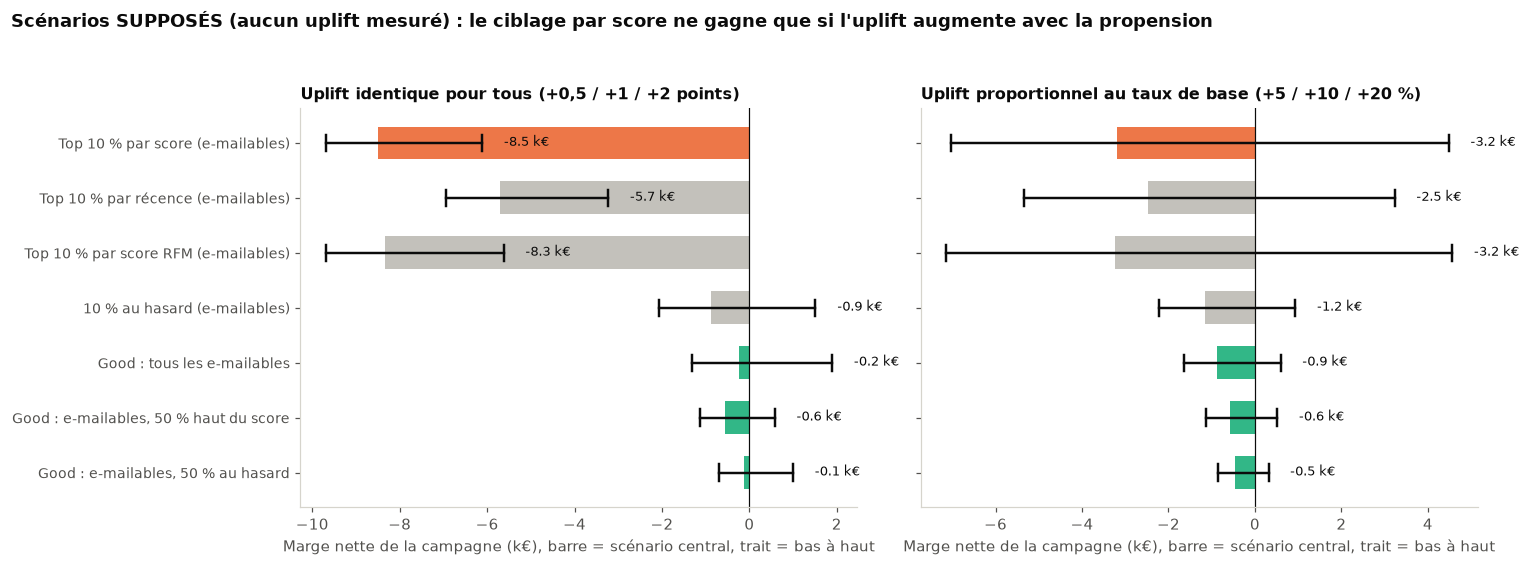

In [17]:
# graphique : marge nette (k€) de la campagne par stratégie, fourchette bas-haut, deux modèles d'uplift
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
order_s = list(T4.index)[::-1]
cols_s = {n: (c.GREEN if n.startswith('Good') else c.ACCENT if 'score' in n and 'RFM' not in n else c.GREY) for n in order_s}
for ax, mode, ttl in [(axes[0], 'abs', 'Uplift identique pour tous (+0,5 / +1 / +2 points)'), (axes[1], 'rel', 'Uplift proportionnel au taux de base (+5 / +10 / +20 %)')]:
    for i_, n in enumerate(order_s):
        lo_, mid_, hi_ = [T4.loc[n, f'net_{mode}_{l}'] / 1000 for l in ['bas', 'central', 'haut']]
        ax.barh(i_, mid_, color=cols_s[n], alpha=0.9, height=0.6)
        ax.plot([lo_, hi_], [i_, i_], color=c.INK, lw=1.6); ax.plot([lo_, lo_], [i_ - 0.15, i_ + 0.15], color=c.INK, lw=1.6); ax.plot([hi_, hi_], [i_ - 0.15, i_ + 0.15], color=c.INK, lw=1.6)
        ax.text(max(hi_, mid_) + 0.5, i_ + 0.02, f"{mid_:.1f} k€", va='center', fontsize=8.5)
    ax.axvline(0, color=c.INK, lw=0.8); ax.set_yticks(range(len(order_s))); ax.set_yticklabels(order_s, fontsize=9)
    ax.set_xlabel('Marge nette de la campagne (k€), barre = scénario central, trait = bas à haut'); ax.set_title(ttl, fontsize=10.5, loc='left')
fig.suptitle("Scénarios SUPPOSÉS (aucun uplift mesuré) : le ciblage par score ne gagne que si l'uplift augmente avec la propension", x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.94)); savefig(fig, '07_scenarios_roi')

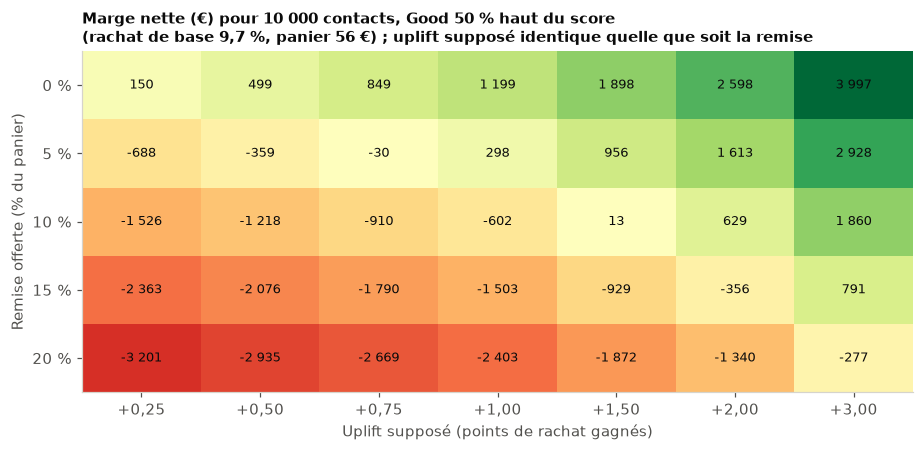

In [18]:
# sensibilité : Good 50 % haut du score, marge nette pour 10 000 contacts selon uplift et remise (modèle absolu)
sel = 'Good : e-mailables, 50 % haut du score'
p_s, b_s = T4.loc[sel, 'p_rachat'] / 100, T4.loc[sel, 'panier']
ups = np.array([0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03]); dis = np.array([0, 0.05, 0.10, 0.15, 0.20])
grid = np.array([[net_per_contact(p_s, b_s, u_, 'abs', discount=d_)['net'] * 10000 for u_ in ups] for d_ in dis])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(grid, cmap='RdYlGn', vmin=-np.abs(grid).max(), vmax=np.abs(grid).max(), aspect='auto')
ax.set_xticks(range(len(ups))); ax.set_xticklabels([f"+{100*u_:.2f}".replace('.', ',') for u_ in ups]); ax.set_yticks(range(len(dis))); ax.set_yticklabels([f"{100*d_:.0f} %" for d_ in dis])
for i_ in range(len(dis)):
    for j_ in range(len(ups)): ax.text(j_, i_, f"{grid[i_, j_]:,.0f}".replace(',', ' '), ha='center', va='center', fontsize=8.5)
ax.set_xlabel('Uplift supposé (points de rachat gagnés)'); ax.set_ylabel('Remise offerte (% du panier)')
ax.set_title(f"Marge nette (€) pour 10 000 contacts, Good 50 % haut du score\n(rachat de base {p_s*100:.1f} %, panier {b_s:.0f} €) ; uplift supposé identique quelle que soit la remise".replace('.', ','), fontsize=9.5, loc='left')
fig.tight_layout(); savefig(fig, '07_sensibilite_remise')

In [19]:
sc, rd, g_all, g_half, g_rand = [T4.loc[n] for n in ['Top 10 % par score (e-mailables)', '10 % au hasard (e-mailables)', 'Good : tous les e-mailables', 'Good : e-mailables, 50 % haut du score', 'Good : e-mailables, 50 % au hasard']]
rec_ = T4.loc['Top 10 % par récence (e-mailables)']
rfm_ = T4.loc['Top 10 % par score RFM (e-mailables)']
say(f"""**Lecture** *(🟦 `p` et `b` mesurés ; les montants en € dépendent des hypothèses 🟧 : seuls les ordres de grandeur et les comparaisons sont à retenir)*
- **Ce qui est mesuré** : parmi les e-mailables, le top 10 % par score a un rachat de base de **{pc(sc['p_rachat'])}** contre {pc(rd['p_rachat'])} au hasard, {pc(rec_['p_rachat'])} par la règle de récence et {pc(rfm_['p_rachat'])} par le score RFM. Il y a **{fr(sc['rachats_de_base'])} rachats de base** à capter contre {fr(rd['rachats_de_base'])} au hasard. 
  Mais ces rachats auraient eu lieu sans e-mail : **la remise est versée à ces clients-là aussi**.
- **Avec une remise de 10 %, le scénario central n'est rentable pour aucune stratégie.** Marge nette à +1 point : top 10 % par score {fr(sc['net_abs_central']/1000,1)} k€, hasard {fr(rd['net_abs_central']/1000,1)} k€, tout Good {fr(g_all['net_abs_central']/1000,1)} k€. 
  Le **seuil de rentabilité** est de **{g_all['seuil_uplift_abs']*100:.2f} point** pour tout Good, {rd['seuil_uplift_abs']*100:.2f} au hasard, **{sc['seuil_uplift_abs']*100:.2f} pour le top 10 % par score** : plus la cible achète déjà, plus l'uplift à obtenir est grand. 
  Seul le scénario haut (+2 points) rend positives les stratégies larges (tout Good : {fr(g_all['net_abs_haut']/1000,1)} k€ ; hasard : {fr(rd['net_abs_haut']/1000,1)} k€) ; le top 10 % par score reste à {fr(sc['net_abs_haut']/1000,1)} k€.
- **Si l'uplift est proportionnel au taux de base** (hypothèse favorable au score), le top 10 % par score devient rentable **dès que l'uplift relatif dépasse environ {sc['seuil_uplift_rel']*100:.0f} %** (hasard : {rd['seuil_uplift_rel']*100:.0f} %) et c'est lui qui rapporte le plus au-delà : à +20 %, {fr(sc['net_rel_haut']/1000,1)} k€ contre {fr(rd['net_rel_haut']/1000,1)} k€ au hasard ; en dessous (central, +10 %) il perd {fr(-sc['net_rel_central']/1000,1)} k€. 
  Ce résultat est **une conséquence de l'hypothèse** (un client qui rachète déjà à {pc(sc['p_rachat'],0)} gagnerait {sc['p_rachat']*ASSUME['uplift_rel']['haut']:.1f} points à +20 %), pas une mesure. **Cibler les plus probables n'est pas cibler les plus influençables.**
- **À l'intérieur de Good**, comparer les 50 % de Good au meilleur score ({fr(g_half['clients_contactés'])} clients, rachat de base {pc(g_half['p_rachat'])}) à un même nombre de clients tirés au hasard dans Good ({pc(g_rand['p_rachat'])}) : à uplift identique (+1 pt), **le tri par score est moins rentable** ({fr(g_half['net_abs_central']/1000,1)} contre {fr(g_rand['net_abs_central']/1000,1)} k€), parce qu'il sélectionne des clients qui bénéficient déjà plus souvent de la remise ; 
  sous uplift proportionnel, il est un peu meilleur dans le scénario haut ({fr(g_half['net_rel_haut']/1000,1)} contre {fr(g_rand['net_rel_haut']/1000,1)} k€) et équivalent au centre. **Le score ne garantit donc pas un meilleur ciblage dans Good : il faut mesurer l'uplift par tranche de score** (section 5).
- **Seuil de remise** (marge nette nulle pour un uplift de +1 point) : {pc(100*g_all['remise_max_abs'],0)} du panier pour tout Good, {pc(100*rd['remise_max_abs'],0)} au hasard, {pc(100*sc['remise_max_abs'],0)} pour le top 10 % par score. Avec une remise de 5 %, le seuil de rentabilité tombe à {g_all['seuil_abs_d5']*100:.2f} point pour tout Good ; 
  avec **un simple rappel sans remise** (seul le coût d'envoi à couvrir), à {g_all['seuil_abs_d0']*100:.2f} point : mais l'uplift d'un rappel sans offre est certainement plus faible, et c'est précisément ce qu'un test à plusieurs bras permet de comparer.
- **Sensibilité** : si tous les acheteurs utilisent la remise (au lieu de {pc(100*ASSUME['redeem'],0)} supposés), le seuil de rentabilité de tout Good monte à {g_all['seuil_abs_r100']*100:.1f} points. La figure de sensibilité (remise × uplift) montre où la marge devient négative.""")

**Lecture** *(🟦 `p` et `b` mesurés ; les montants en € dépendent des hypothèses 🟧 : seuls les ordres de grandeur et les comparaisons sont à retenir)*
- **Ce qui est mesuré** : parmi les e-mailables, le top 10 % par score a un rachat de base de **32,3 %** contre 8,8 % au hasard, 23,0 % par la règle de récence et 28,8 % par le score RFM. Il y a **6 473 rachats de base** à capter contre 1 763 au hasard. 
  Mais ces rachats auraient eu lieu sans e-mail : **la remise est versée à ces clients-là aussi**.
- **Avec une remise de 10 %, le scénario central n'est rentable pour aucune stratégie.** Marge nette à +1 point : top 10 % par score -8,5 k€, hasard -0,9 k€, tout Good -0,2 k€. 
  Le **seuil de rentabilité** est de **1,11 point** pour tout Good, 1,37 au hasard, **4,57 pour le top 10 % par score** : plus la cible achète déjà, plus l'uplift à obtenir est grand. 
  Seul le scénario haut (+2 points) rend positives les stratégies larges (tout Good : 1,9 k€ ; hasard : 1,5 k€) ; le top 10 % par score reste à -6,1 k€.
- **Si l'uplift est proportionnel au taux de base** (hypothèse favorable au score), le top 10 % par score devient rentable **dès que l'uplift relatif dépasse environ 14 %** (hasard : 16 %) et c'est lui qui rapporte le plus au-delà : à +20 %, 4,5 k€ contre 0,9 k€ au hasard ; en dessous (central, +10 %) il perd 3,2 k€. 
  Ce résultat est **une conséquence de l'hypothèse** (un client qui rachète déjà à 32 % gagnerait 6,5 points à +20 %), pas une mesure. **Cibler les plus probables n'est pas cibler les plus influençables.**
- **À l'intérieur de Good**, comparer les 50 % de Good au meilleur score (9 215 clients, rachat de base 9,7 %) à un même nombre de clients tirés au hasard dans Good (7,0 %) : à uplift identique (+1 pt), **le tri par score est moins rentable** (-0,6 contre -0,1 k€), parce qu'il sélectionne des clients qui bénéficient déjà plus souvent de la remise ; 
  sous uplift proportionnel, il est un peu meilleur dans le scénario haut (0,5 contre 0,3 k€) et équivalent au centre. **Le score ne garantit donc pas un meilleur ciblage dans Good : il faut mesurer l'uplift par tranche de score** (section 5).
- **Seuil de remise** (marge nette nulle pour un uplift de +1 point) : 9 % du panier pour tout Good, 7 % au hasard, 2 % pour le top 10 % par score. Avec une remise de 5 %, le seuil de rentabilité tombe à 0,60 point pour tout Good ; 
  avec **un simple rappel sans remise** (seul le coût d'envoi à couvrir), à 0,14 point : mais l'uplift d'un rappel sans offre est certainement plus faible, et c'est précisément ce qu'un test à plusieurs bras permet de comparer.
- **Sensibilité** : si tous les acheteurs utilisent la remise (au lieu de 30 % supposés), le seuil de rentabilité de tout Good monte à 4,9 points. La figure de sensibilité (remise × uplift) montre où la marge devient négative.

## 5. Dimensionner le test A/B (groupe témoin) et plan d'action

**Pourquoi un test ?** Le score classe les clients selon leur propension à acheter. Il ne dit pas *combien d'achats l'e-mail provoque*. Seul un **groupe témoin** (client éligible, tiré au sort, à qui on n'envoie rien) mesure l'uplift. Cours : test A/B, groupe témoin, suivi du modèle (slides 74-76, 89).

**Plan** : population = tous les e-mailables de Good (effectif de la base complète dans les tableaux ci-dessous), répartis **au hasard** (stratifié par tranche de score A / B / C) entre *traités* et *témoins*. On mesure l'uplift global puis, avec moins de puissance, par tranche de score.
**Paramètres** : seuil de signification 5 % (bilatéral), puissance 80 %, test de comparaison de deux proportions (taille d'effet de Cohen h, `statsmodels`).

In [20]:
pw = NormalIndPower()
ALPHA, POWER = 0.05, 0.80
def n_total(p0, delta, ctrl_share):
    es = proportion_effectsize(p0 + delta, p0)
    n_ctrl = pw.solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=(1 - ctrl_share) / ctrl_share)
    return n_ctrl / ctrl_share
def mde(p0, n_tot, ctrl_share, n_treat=None):
    n_ctrl = n_tot * ctrl_share
    ratio = (1 - ctrl_share) / ctrl_share if n_treat is None else n_treat / n_ctrl
    es = pw.solve_power(effect_size=None, nobs1=n_ctrl, alpha=ALPHA, power=POWER, ratio=ratio)
    p1 = np.sin(np.arcsin(np.sqrt(p0)) + es / 2) ** 2
    return p1 - p0

p0_all = T4.loc['Good : tous les e-mailables', 'p_rachat'] / 100
p0_half = T4.loc['Good : e-mailables, 50 % haut du score', 'p_rachat'] / 100
N_AB = n_good_email_full
rows = []
for label, p0 in [('Good tous e-mailables', p0_all), ('Good 50 % haut du score', p0_half)]:
    for delta in [0.005, 0.01, 0.015, 0.02, 0.03]:
        for cs in [0.5, 0.3, 0.2]:
            rows.append(dict(population=label, rachat_de_base=100 * p0, uplift_pts=100 * delta, uplift_relatif=100 * delta / p0, part_témoin=cs,
                             n_total_requis=n_total(p0, delta, cs), n_témoin=n_total(p0, delta, cs) * cs, tient_dans_Good=n_total(p0, delta, cs) <= N_AB))
AB = pd.DataFrame(rows)
mde_rows = []
for label, p0, n_ in [('Good tous e-mailables', p0_all, N_AB), ('Good 50 % haut du score', p0_half, n_AB_full)]:
    for cs in [0.5, 0.3, 0.2, 0.1]:
        d_ = mde(p0, n_, cs); mde_rows.append(dict(population=label, n=n_, part_témoin=cs, mde_pts=100 * d_, mde_relatif=100 * d_ / p0))
MDE = pd.DataFrame(mde_rows)
mde_all30 = MDE.query('population=="Good tous e-mailables" and part_témoin==0.3').iloc[0]
mde_all20 = MDE.query('population=="Good tous e-mailables" and part_témoin==0.2').iloc[0]
mde_3arms = 100 * mde(p0_all, N_AB, 0.3, n_treat=0.35 * N_AB)
mde_half30 = MDE.query('population=="Good 50 % haut du score" and part_témoin==0.3').iloc[0]
# réduction de variance possible en ajustant sur le score (régression de y sur le score, dans Good e-mailable)
sg_ = score[good_em]; yg_ = y[good_em]
r2 = np.corrcoef(sg_, yg_)[0, 1] ** 2
# groupes par tranche de score pour la lecture secondaire
p0_tier = {t: tiers.loc[i, 'rachat % (🟦, e-mailables)'] / 100 for t, i in zip('ABC', tiers.index)}
n_tier = {t: tiers.loc[i, 'e-mailables (base complète)'] for t, i in zip('ABC', tiers.index)}
mde_tier = pd.DataFrame({t: dict(rachat_de_base=100 * p0_tier[t], n=n_tier[t], mde_pts=100 * mde(p0_tier[t], n_tier[t], 0.3)) for t in 'ABC'}).T
display(Markdown("**Taille d'échantillon requise** (total traités + témoins) pour détecter un uplift absolu, test bilatéral 5 %, puissance 80 %"))
ab_tab = AB.pivot_table(index=['population', 'uplift_pts', 'uplift_relatif'], columns='part_témoin', values='n_total_requis').round(0)
ab_tab.columns = [f"{int(100*x)} % de témoins" for x in ab_tab.columns]
ab_tab = ab_tab.reset_index(); ab_tab['uplift_relatif'] = ab_tab['uplift_relatif'].round(0).astype(int)
ab_tab = ab_tab.rename(columns={'population': 'Population', 'uplift_pts': 'Uplift cherché (points)', 'uplift_relatif': 'soit (% du taux de base)'}).set_index('Population')
show(ab_tab, precision=1)
display(Markdown(f"**Effet minimal détectable (MDE)** avec l'effectif disponible (base complète) : {fr(N_AB)} e-mailables Good (tous), {fr(n_AB_full)} (50 % haut du score)"))
show(MDE.rename(columns={'population': 'Population', 'n': 'Effectif', 'part_témoin': 'Part de témoins', 'mde_pts': 'MDE (points)', 'mde_relatif': 'MDE (% du taux de base)'}).set_index('Population'), precision=2)
display(Markdown("**Lecture par tranche de score (30 % de témoins)** : l'effectif ne permet de détecter, par tranche, que des effets plus grands"))
show(mde_tier.rename(columns={'rachat_de_base': 'Rachat de base (%)', 'n': 'Effectif e-mailable', 'mde_pts': 'MDE (points)'}).rename_axis('Tranche'), precision=2)
say(f"Ajuster l'analyse sur le score (covariable) réduirait la variance de {100*r2:.1f} % seulement (R² du rachat sur le score dans Good e-mailables) : l'ajustement aide un peu, il ne change pas la taille du test.")

**Taille d'échantillon requise** (total traités + témoins) pour détecter un uplift absolu, test bilatéral 5 %, puissance 80 %

,Uplift cherché (points),soit (% du taux de base),20 % de témoins,30 % de témoins,50 % de témoins
Population,,,,,
Good 50 % haut du score,"0,5",5,176 253,134 288,112 802
Good 50 % haut du score,"1,0",10,45 023,34 303,28 815
Good 50 % haut du score,"1,5",15,20 429,15 565,13 075
Good 50 % haut du score,"2,0",21,11 723,8 932,7 503
Good 50 % haut du score,"3,0",31,5 411,4 122,3 463
Good tous e-mailables,"0,5",7,131 250,100 000,84 000
Good tous e-mailables,"1,0",14,33 832,25 777,21 653
Good tous e-mailables,"1,5",22,15 480,11 794,9 907
Good tous e-mailables,"2,0",29,8 952,6 821,5 729


**Effet minimal détectable (MDE)** avec l'effectif disponible (base complète) : 17 486 e-mailables Good (tous), 9 215 (50 % haut du score)

,Effectif,Part de témoins,MDE (points),MDE (% du taux de base)
Population,,,,
Good tous e-mailables,17 486,"0,50","1,12","16,04"
Good tous e-mailables,17 486,"0,30","1,22","17,56"
Good tous e-mailables,17 486,"0,20","1,41","20,22"
Good tous e-mailables,17 486,"0,10","1,90","27,34"
Good 50 % haut du score,9 215,"0,50","1,80","18,47"
Good 50 % haut du score,9 215,"0,30","1,97","20,22"
Good 50 % haut du score,9 215,"0,20","2,27","23,31"
Good 50 % haut du score,9 215,"0,10","3,07","31,54"


**Lecture par tranche de score (30 % de témoins)** : l'effectif ne permet de détecter, par tranche, que des effets plus grands

,Rachat de base (%),Effectif e-mailable,MDE (points)
Tranche,,,
A,"13,80",3 812,"3,59"
B,"6,86",5 403,"2,25"
C,"3,88",8 271,"1,40"


Ajuster l'analyse sur le score (covariable) réduirait la variance de 2,8 % seulement (R² du rachat sur le score dans Good e-mailables) : l'ajustement aide un peu, il ne change pas la taille du test.

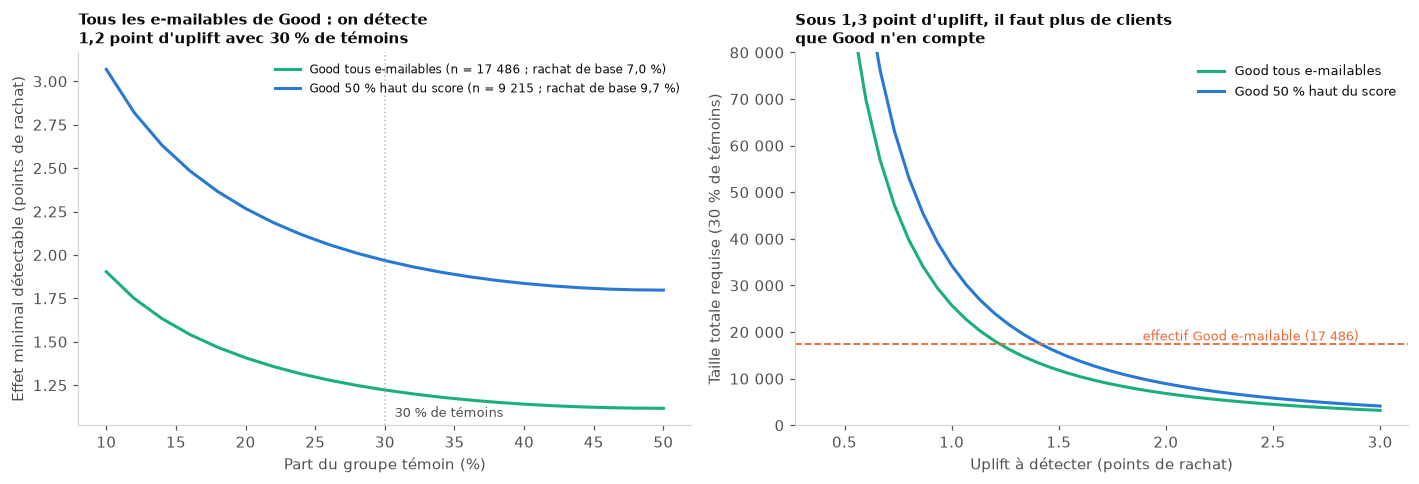

In [21]:
# graphique : MDE en fonction de la part de témoins et de l'effectif ; taille requise pour 1 point d'uplift
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
shares = np.linspace(0.1, 0.5, 21)
for (label, p0, n_), col in zip([('Good tous e-mailables', p0_all, N_AB), ('Good 50 % haut du score', p0_half, n_AB_full)], [c.GREEN, c.BLUE]):
    ax.plot(shares * 100, [100 * mde(p0, n_, s_) for s_ in shares], color=col, lw=2, label=f"{label} (n = {fr(n_)} ; rachat de base {p0*100:.1f} %)".replace('.', ','))
ax.axvline(30, color=c.GREY, ls=':', lw=1); ax.text(30.7, ax.get_ylim()[0] + 0.03, '30 % de témoins', fontsize=8.5, color=c.INK2, va='bottom')
ax.set_xlabel('Part du groupe témoin (%)'); ax.set_ylabel('Effet minimal détectable (points de rachat)')
ax.set_title(f"Tous les e-mailables de Good : on détecte\n{mde_all30['mde_pts']:.1f} point d'uplift avec 30 % de témoins".replace('.', ','), fontsize=10, loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper right')
ax = axes[1]
dl = np.linspace(0.004, 0.03, 40)
for (label, p0), col in zip([('Good tous e-mailables', p0_all), ('Good 50 % haut du score', p0_half)], [c.GREEN, c.BLUE]):
    ax.plot(dl * 100, [n_total(p0, d_, 0.3) for d_ in dl], color=col, lw=2, label=label)
ax.axhline(N_AB, color=c.ACCENT, ls='--', lw=1.2); ax.text(2.9, N_AB * 1.04, f"effectif Good e-mailable ({fr(N_AB)})", ha='right', color=c.ACCENT, fontsize=8.5)
ax.set_ylim(0, 80000); ax.set_xlabel('Uplift à détecter (points de rachat)'); ax.set_ylabel('Taille totale requise (30 % de témoins)')
d_cross = min(d_ for d_ in dl if n_total(p0_all, d_, 0.3) <= N_AB)
ax.set_title(f"Sous {100*d_cross:.1f} point d'uplift, il faut plus de clients\nque Good n'en compte".replace('.', ','), fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=8.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fr(v)))
fig.tight_layout(); savefig(fig, '07_ab_dimensionnement')

In [22]:
n1pt = AB.query('population=="Good tous e-mailables" and uplift_pts==1.0 and part_témoin==0.3').iloc[0]
tient_txt = "c'est dans l'effectif" if n1pt['tient_dans_Good'] else "c'est plus que l'effectif disponible"
say(f"""**Conclusion de dimensionnement** (🟦 pour les taux de base, 🟧 pour les effets cherchés)
- **Plan retenu : tous les e-mailables de Good ({fr(N_AB)} clients), 70 % traités / 30 % témoins** (témoin : {fr(0.3*N_AB)} clients). **Effet minimal détectable : {mde_all30['mde_pts']:.2f} point** de rachat ({pc(mde_all30['mde_relatif'], 0)} du taux de base de {pc(100*p0_all)}).
  Avec 20 % de témoins : {mde_all20['mde_pts']:.2f} point. Pour un uplift de 1 point, il faudrait {fr(n1pt['n_total_requis'])} clients au total pour 30 % de témoins : {tient_txt} (donc l'uplift de **+1 point, scénario central, est à la limite de ce que le test peut confirmer**, un +0,5 point ne serait pas détectable). Le seuil de rentabilité du bras « remise 10 % » ({g_all['seuil_uplift_abs']*100:.2f} point) est du même ordre que l'effet minimal détectable ({mde_all30['mde_pts']:.2f} point) : **le test peut juste trancher la rentabilité de la remise, pas bien plus**.
- **Trois bras** (30 % témoin, 35 % rappel sans remise, 35 % offre) : effet minimal détectable de chaque bras contre le témoin = {mde_3arms:.2f} point. À réserver à un second tour si le premier ne suffit pas.
- **Limiter le test aux 50 % de Good au meilleur score** ({fr(n_AB_full)} clients) le rendrait plus rentable mais **moins puissant** : MDE ≈ {mde_half30['mde_pts']:.1f} points. Mieux vaut tester tout le segment (tranches A, B, C tirées au sort), puis **n'étendre que là où l'uplift mesuré dépasse le seuil de rentabilité**.
- **Lecture par tranche** (secondaire) : A, B et C ne permettent de détecter que {mde_tier.loc['A','mde_pts']:.1f}, {mde_tier.loc['B','mde_pts']:.1f} et {mde_tier.loc['C','mde_pts']:.1f} points respectivement : ne pas sur-interpréter les différences entre tranches.
- Pour gagner en puissance : **plusieurs vagues sur plusieurs mois** (même clients tirés au sort chaque fois, avec rotation du témoin), ou **élargir** au reste de la base (autres segments e-mailables), ou **mesurer le chiffre d'affaires par client** (plus informatif qu'un 0/1 mais plus variable). L'ajustement sur le score ne retire que {100*r2:.0f} % de variance.

**KPI** : *principal* = rachat dans les 30 jours après l'envoi (même définition que la cible du modèle) ; *secondaires* = marge nette par client contacté (CA incrémental × marge − remise − coût), nombre de tickets, panier ; *garde-fous* = désabonnements, plaintes, baisse du panier ou de la fréquence dans les 60 jours (achat avancé).
**Durée** : 4 semaines de fenêtre d'observation (+ 1 semaine pour la lecture et 4 semaines de suivi pour l'effet d'avancement) : environ **9 semaines** de l'envoi à la décision. On évite de « regarder » les résultats en cours de route pour ne pas gonfler les faux positifs.
**Randomisation** : tirage au sort *avant* l'envoi, stratifié par tranche de score A/B/C ; contrôle de l'équilibre sur récence, fréquence, panier, e-mail (aucun écart attendu par construction, à vérifier).
""")

**Conclusion de dimensionnement** (🟦 pour les taux de base, 🟧 pour les effets cherchés)
- **Plan retenu : tous les e-mailables de Good (17 486 clients), 70 % traités / 30 % témoins** (témoin : 5 246 clients). **Effet minimal détectable : 1,22 point** de rachat (18 % du taux de base de 7,0 %).
  Avec 20 % de témoins : 1,41 point. Pour un uplift de 1 point, il faudrait 25 777 clients au total pour 30 % de témoins : c'est plus que l'effectif disponible (donc l'uplift de **+1 point, scénario central, est à la limite de ce que le test peut confirmer**, un +0,5 point ne serait pas détectable). Le seuil de rentabilité du bras « remise 10 % » (1,11 point) est du même ordre que l'effet minimal détectable (1,22 point) : **le test peut juste trancher la rentabilité de la remise, pas bien plus**.
- **Trois bras** (30 % témoin, 35 % rappel sans remise, 35 % offre) : effet minimal détectable de chaque bras contre le témoin = 1,40 point. À réserver à un second tour si le premier ne suffit pas.
- **Limiter le test aux 50 % de Good au meilleur score** (9 215 clients) le rendrait plus rentable mais **moins puissant** : MDE ≈ 2,0 points. Mieux vaut tester tout le segment (tranches A, B, C tirées au sort), puis **n'étendre que là où l'uplift mesuré dépasse le seuil de rentabilité**.
- **Lecture par tranche** (secondaire) : A, B et C ne permettent de détecter que 3,6, 2,2 et 1,4 points respectivement : ne pas sur-interpréter les différences entre tranches.
- Pour gagner en puissance : **plusieurs vagues sur plusieurs mois** (même clients tirés au sort chaque fois, avec rotation du témoin), ou **élargir** au reste de la base (autres segments e-mailables), ou **mesurer le chiffre d'affaires par client** (plus informatif qu'un 0/1 mais plus variable). L'ajustement sur le score ne retire que 3 % de variance.

**KPI** : *principal* = rachat dans les 30 jours après l'envoi (même définition que la cible du modèle) ; *secondaires* = marge nette par client contacté (CA incrémental × marge − remise − coût), nombre de tickets, panier ; *garde-fous* = désabonnements, plaintes, baisse du panier ou de la fréquence dans les 60 jours (achat avancé).
**Durée** : 4 semaines de fenêtre d'observation (+ 1 semaine pour la lecture et 4 semaines de suivi pour l'effet d'avancement) : environ **9 semaines** de l'envoi à la décision. On évite de « regarder » les résultats en cours de route pour ne pas gonfler les faux positifs.
**Randomisation** : tirage au sort *avant* l'envoi, stratifié par tranche de score A/B/C ; contrôle de l'équilibre sur récence, fréquence, panier, e-mail (aucun écart attendu par construction, à vérifier).


### Plan d'action en 3 étapes

In [23]:
say(f"""| Étape | Quoi | Quand | Critère de passage |
|---|---|---|---|
| **1. Préparer** | Scorer toute la base e-mailable avec le modèle final ; extraire Good ({fr(N_AB)} e-mailables) ; tirer 30 % de témoins, stratifiés par tranche de score ; valider le consentement et la création ; fixer le seuil de rentabilité avec la finance (uplift ≥ {g_all['seuil_uplift_abs']*100:.1f} point pour Good avec une remise de {pc(100*ASSUME['discount'],0)}, hypothèse 🟧) avec la finance | J − 14 à J − 1 | Équilibre témoin / traité vérifié |
| **2. Tester** | Envoi le jeudi ou vendredi matin aux traités (offre −10 % week-end, variante sans remise sur un sous-groupe si la taille le permet) ; relance J + 3 ; pour le top 10 % hors Good : rappel sans remise en attendant la mesure (limite la cannibalisation) | J0 à J + 30 | Aucune lecture intermédiaire de la significativité |
| **3. Décider et apprendre** | Mesurer l'uplift (traités − témoins), l'IC et la marge nette ; si uplift ≥ seuil : étendre aux tranches rentables et aux autres segments ; sinon : arrêter la remise, garder un rappel sans remise ; **ré-entraîner le score** avec les nouvelles données (boucle de rétroaction) | J + 37 à J + 60 | Marge nette > 0 *et* pas d'effet d'avancement |""")

| Étape | Quoi | Quand | Critère de passage |
|---|---|---|---|
| **1. Préparer** | Scorer toute la base e-mailable avec le modèle final ; extraire Good (17 486 e-mailables) ; tirer 30 % de témoins, stratifiés par tranche de score ; valider le consentement et la création ; fixer le seuil de rentabilité avec la finance (uplift ≥ 1,1 point pour Good avec une remise de 10 %, hypothèse 🟧) avec la finance | J − 14 à J − 1 | Équilibre témoin / traité vérifié |
| **2. Tester** | Envoi le jeudi ou vendredi matin aux traités (offre −10 % week-end, variante sans remise sur un sous-groupe si la taille le permet) ; relance J + 3 ; pour le top 10 % hors Good : rappel sans remise en attendant la mesure (limite la cannibalisation) | J0 à J + 30 | Aucune lecture intermédiaire de la significativité |
| **3. Décider et apprendre** | Mesurer l'uplift (traités − témoins), l'IC et la marge nette ; si uplift ≥ seuil : étendre aux tranches rentables et aux autres segments ; sinon : arrêter la remise, garder un rappel sans remise ; **ré-entraîner le score** avec les nouvelles données (boucle de rétroaction) | J + 37 à J + 60 | Marge nette > 0 *et* pas d'effet d'avancement |

## 6. Limites, risques et ce que ce notebook ne dit pas

In [24]:
say(f"""**Ce qui est solide (🟦)** : le score classe mieux que la récence seule ({pc(best['précision'])} contre {pc(rec['précision'])} de précision dans le top 10 %), c'est mesuré hors-échantillon et stable (IC95 de l'écart = {100*np.percentile(d_boot,2.5):.1f} à {100*np.percentile(d_boot,97.5):.1f} points). Le tri fonctionne aussi à l'intérieur de Good (AUC intra {gd['auc_intra']:.3f}).

**Ce qui n'est pas démontré, et pourquoi**
1. **Propension ≠ effet causal.** Le score prédit *qui achètera*, pas *qui achètera à cause de l'e-mail*. Les clients du top 10 % (rachat {pc(sc['p_rachat'])} chez les e-mailables) achètent déjà souvent : une grande partie de leurs achats aurait eu lieu sans e-mail, et remiser leur panier est alors un coût pur (cannibalisation de marge) ; la part exacte est inconnue sans groupe témoin.
   Aucune donnée d'exposition à une campagne passée ne permet d'estimer un uplift. **Tous les montants en € de la section 4 sont des scénarios**, pas des prévisions. Cibler les plus influençables demanderait un modèle d'uplift, hors programme du cours, alimenté par les données du test de la section 5.
2. **Cible étroite.** Le rachat est observé sur un mois mais correspond à environ 1,9 jour d'activité (7,7 % de la base) : la probabilité « d'acheter » est sous-estimée, et la part de clients « acquis » parmi les non-racheteurs est donc plus grande qu'il n'y paraît. Les probabilités du modèle sont des classements, pas des taux mensuels réels.
3. **Un seul mois cible (août 2020), un seul découpage.** Août 2019 était le 2e mois le plus actif de l'historique ; l'effet week-end peut être un effet de calendrier ; le modèle n'a pas appris la saisonnalité. Les performances sur un autre mois peuvent différer : suivi de la dérive et ré-entraînement nécessaires.
4. **Cannibalisation et achat avancé.** Une offre peut déplacer des achats plutôt que les créer (le client achète trois jours plus tôt). C'est pour cela que le test suit les 60 jours qui suivent l'envoi. Une remise peut aussi **habituer** à attendre l'offre.
5. **Joignabilité.** {pc(100*(1-email.mean()), 0)} des clients n'ont pas d'e-mail. Le top 10 % « pur » contient {pc(100-best['pct_joignables'], 0)} de clients injoignables : la campagne e-mail ne touche pas ceux-là. Les e-mailables rachètent plus ({pc(100*y[email].mean())} contre {pc(100*y[~email].mean())}) : ce sont des clients mieux identifiés, pas un effet de l'e-mail.
6. **Taille du test.** Un uplift d'un point est à la limite de ce que le test de Good peut détecter (section 5) : un résultat non significatif ne prouvera pas l'absence d'effet.
7. **Données et hypothèses économiques.** Marge, coût de contact, remise, taux d'utilisation sont supposés (aucune donnée de coût ni de marge). Le panier est celui des 12 mois passés, pas celui du rachat. Une campagne supposée provoquer *un seul* ticket supplémentaire ignore l'effet sur la fréquence.
8. **Éthique et RGPD.** Le modèle utilise peu les variables d'identité (notebook 04 : −0,0002 d'AUC sans elles) : on peut les retirer sans coût. Le ciblage doit respecter le consentement e-mail ; ne pas cibler par proxy d'âge ou de territoire.

**Pistes** : modèle d'uplift après le premier test ; plusieurs coupures temporelles ; données ouvertes (revenus, calendrier, météo) ; canaux hors e-mail pour les clients de Good injoignables par e-mail ; mesurer la lassitude (pression marketing).
""")

**Ce qui est solide (🟦)** : le score classe mieux que la récence seule (40,6 % contre 23,5 % de précision dans le top 10 %), c'est mesuré hors-échantillon et stable (IC95 de l'écart = 16,5 à 17,9 points). Le tri fonctionne aussi à l'intérieur de Good (AUC intra 0,677).

**Ce qui n'est pas démontré, et pourquoi**
1. **Propension ≠ effet causal.** Le score prédit *qui achètera*, pas *qui achètera à cause de l'e-mail*. Les clients du top 10 % (rachat 32,3 % chez les e-mailables) achètent déjà souvent : une grande partie de leurs achats aurait eu lieu sans e-mail, et remiser leur panier est alors un coût pur (cannibalisation de marge) ; la part exacte est inconnue sans groupe témoin.
   Aucune donnée d'exposition à une campagne passée ne permet d'estimer un uplift. **Tous les montants en € de la section 4 sont des scénarios**, pas des prévisions. Cibler les plus influençables demanderait un modèle d'uplift, hors programme du cours, alimenté par les données du test de la section 5.
2. **Cible étroite.** Le rachat est observé sur un mois mais correspond à environ 1,9 jour d'activité (7,7 % de la base) : la probabilité « d'acheter » est sous-estimée, et la part de clients « acquis » parmi les non-racheteurs est donc plus grande qu'il n'y paraît. Les probabilités du modèle sont des classements, pas des taux mensuels réels.
3. **Un seul mois cible (août 2020), un seul découpage.** Août 2019 était le 2e mois le plus actif de l'historique ; l'effet week-end peut être un effet de calendrier ; le modèle n'a pas appris la saisonnalité. Les performances sur un autre mois peuvent différer : suivi de la dérive et ré-entraînement nécessaires.
4. **Cannibalisation et achat avancé.** Une offre peut déplacer des achats plutôt que les créer (le client achète trois jours plus tôt). C'est pour cela que le test suit les 60 jours qui suivent l'envoi. Une remise peut aussi **habituer** à attendre l'offre.
5. **Joignabilité.** 45 % des clients n'ont pas d'e-mail. Le top 10 % « pur » contient 36 % de clients injoignables : la campagne e-mail ne touche pas ceux-là. Les e-mailables rachètent plus (8,8 % contre 6,4 %) : ce sont des clients mieux identifiés, pas un effet de l'e-mail.
6. **Taille du test.** Un uplift d'un point est à la limite de ce que le test de Good peut détecter (section 5) : un résultat non significatif ne prouvera pas l'absence d'effet.
7. **Données et hypothèses économiques.** Marge, coût de contact, remise, taux d'utilisation sont supposés (aucune donnée de coût ni de marge). Le panier est celui des 12 mois passés, pas celui du rachat. Une campagne supposée provoquer *un seul* ticket supplémentaire ignore l'effet sur la fréquence.
8. **Éthique et RGPD.** Le modèle utilise peu les variables d'identité (notebook 04 : −0,0002 d'AUC sans elles) : on peut les retirer sans coût. Le ciblage doit respecter le consentement e-mail ; ne pas cibler par proxy d'âge ou de territoire.

**Pistes** : modèle d'uplift après le premier test ; plusieurs coupures temporelles ; données ouvertes (revenus, calendrier, météo) ; canaux hors e-mail pour les clients de Good injoignables par e-mail ; mesurer la lassitude (pression marketing).


## 7. Sorties : tableaux, chiffres clés et résumé

In [25]:
# ---- tableaux ----
c.save_result('07_ciblage_top10', T1.round(4))
c.save_result('07_segments_candidats', T2.round(4))
c.save_result('07_good_tranches_score', tiers.round(4))
c.save_result('07_good_persona', persona.round(3))
c.save_result('07_scenarios_economiques', T4.round(4))
c.save_result('07_ab_dimensionnement', AB.round(4))
c.save_result('07_ab_mde', MDE.round(4))
c.save_result('07_hypotheses', {
    'MESURE (données)': {'taux_rachat_base': float(base), 'taux_rachat_par_strategie': 'voir 07_scenarios_economiques.csv (p_rachat)', 'panier_moyen': 'basket_mean_all moyen des clients ciblés (12 mois)',
                         'effectifs': 'train + test (base complète)', 'scores': f'{MODEL}, hors-échantillon (CV 5 plis)'},
    'SUPPOSE (hypothèses)': {k: v for k, v in ASSUME.items()},
    'test_AB': {'alpha': ALPHA, 'puissance': POWER, 'part_temoin_retenue': 0.3}})
key = {
    'modele_score': MODEL, 'n_train': int(N), 'n_base_complete': int(N_FULL), 'top10_k_train': int(K10), 'top10_k_base_complete': int(K10_FULL),
    'taux_rachat_base': float(base),
    'top10_precision_lgbm': float(best['précision'] / 100), 'top10_rappel_lgbm': float(best['rappel'] / 100), 'top10_lift_lgbm': float(best['lift']),
    'top10_precision_recence': float(rec['précision'] / 100), 'top10_precision_rfm': float(T1.loc['Score RFM', 'précision'] / 100),
    'rachats_captes_lgbm': float(best['rachats_captés']), 'rachats_captes_en_plus_hasard': float(best['captés_en_plus']),
    'rachats_captes_en_plus_hasard_ic95': [float(best['extra_bas']), float(best['extra_haut'])],
    'precision_top10_parmi_emailables': float(best['précision_si_email_seul'] / 100), 'pct_top10_joignable_email': float(best['pct_joignables'] / 100),
    'part_top_dans_top10': float(comp.loc['Top', 'Part du top 10 %'] / 100), 'good_dans_top10_n': int(comp.loc['Good', 'Clients dans le top 10 %']),
    'good_n_base_complete': int(gd['n_base_complète']), 'good_n_email_complete': int(gd['n_email_complète']), 'good_rachat': float(gd['rachat'] / 100),
    'good_auc_intra': float(gd['auc_intra']), 'good_part_top30': float(gd['part_top30'] / 100),
    'good_rachat_tranche_A': float(tab_g.loc['A : 20 % haut du score', 'rachat %'] / 100), 'good_rachat_tranche_C': float(tab_g.loc['C : 50 % bas du score', 'rachat %'] / 100),
    'ab_part_temoin': 0.3, 'ab_mde_pts_good_tous': float(mde_all30['mde_pts']), 'ab_n_total_pour_1pt': float(n1pt['n_total_requis']),
    'seuil_rentabilite_uplift_pts_good50': float(g_half['seuil_uplift_abs'] * 100),
    'net_k_eur': {n: {'abs_central': float(T4.loc[n, 'net_abs_central'] / 1000), 'rel_central': float(T4.loc[n, 'net_rel_central'] / 1000)} for n in T4.index},
}
c.save_result('07_key_numbers', key)
print('sorties écrites :', sorted(p.name for p in c.RES.glob('07_*')))

sorties écrites : ['07_ab_dimensionnement.csv', '07_ab_mde.csv', '07_ciblage_top10.csv', '07_good_persona.csv', '07_good_tranches_score.csv', '07_hypotheses.json', '07_key_numbers.json', '07_scenarios_economiques.csv', '07_segments_candidats.csv', '07_summary.md']


In [26]:
L = []
a = L.append
a("# Résumé du notebook 07 : recommandations marketing (usage du score, segment Good, scénarios, test A/B)")
a("")
a("## Chiffres clés (train, 5 plis communs, hors-échantillon ; 🟦 = mesuré, 🟧 = supposé)")
a(f"- 🟦 **Top 10 % par score `{MODEL}`** ({fr(K10)} clients sur le train, {fr(K10_FULL)} sur la base complète) : précision {pc(best['précision'])}, rappel {pc(best['rappel'])}, lift {best['lift']:.2f} ; hasard : {pc(100*base)} ; règle de récence : {pc(rec['précision'])} ; score RFM : {pc(T1.loc['Score RFM','précision'])} ; logistique Lasso : {pc(T1.loc['Régression logistique (Lasso)','précision'])}.")
a(f"- 🟦 **Rachats captés en plus du hasard** : +{fr(best['captés_en_plus'])} (IC95 {fr(best['extra_bas'])} à {fr(best['extra_haut'])}), soit +{fr(best['rachats_captés']-rec['rachats_captés'])} face à la récence. « Captés » n'est pas « provoqués ».")
a(f"- 🟦 **Joignabilité** : {pc(best['pct_joignables'],0)} du top 10 % a un e-mail ; en choisissant les 10 % parmi les e-mailables : précision {pc(best['précision_si_email_seul'])}.")
a(f"- 🟦 **Composition du top 10 %** : {pc(comp.loc['Top','Part du top 10 %'],0)} Top, {pc(comp.loc['Good','Part du top 10 %'],1)} Good ; Good : {pc(gd['part_top30'],0)} de ses clients dans le top 30 %.")
a(f"- 🟦 **Good** : {fr(gd['n_base_complète'])} clients (base complète), {fr(gd['n_email_complète'])} e-mailables, rachat {pc(gd['rachat'])}, AUC intra-segment {gd['auc_intra']:.3f} ; rachat par tranche de score : A (20 % haut) {pc(tab_g.loc['A : 20 % haut du score','rachat %'])}, B {pc(tab_g.loc['B : 30 % suivants','rachat %'])}, C (50 % bas) {pc(tab_g.loc['C : 50 % bas du score','rachat %'])}.")
a(f"- 🟧 **Scénario central** (contact {ASSUME['contact_cost']} €, marge {pc(100*ASSUME['margin'],0)}, remise {pc(100*ASSUME['discount'],0)}, utilisation {pc(100*ASSUME['redeem'],0)}) : avec une remise de 10 %, **aucune stratégie n'est rentable au centre** (marge nette à +1 pt / +10 % : tout Good {fr(g_all['net_abs_central']/1000,1)} / {fr(g_all['net_rel_central']/1000,1)} k€ ; hasard {fr(rd['net_abs_central']/1000,1)} / {fr(rd['net_rel_central']/1000,1)} ; top 10 % par score {fr(sc['net_abs_central']/1000,1)} / {fr(sc['net_rel_central']/1000,1)} k€) ; en scénario haut (+2 pts / +20 %) : tout Good {fr(g_all['net_abs_haut']/1000,1)} / {fr(g_all['net_rel_haut']/1000,1)}, top 10 % par score {fr(sc['net_abs_haut']/1000,1)} / {fr(sc['net_rel_haut']/1000,1)} k€.")
a(f"- 🟧 **Seuil de rentabilité** (remise 10 %) : tout Good +{g_all['seuil_uplift_abs']*100:.2f} point ; Good 50 % haut du score +{g_half['seuil_uplift_abs']*100:.2f} ; hasard +{rd['seuil_uplift_abs']*100:.2f} ; top 10 % par score +{sc['seuil_uplift_abs']*100:.2f} point (≈ +{sc['seuil_uplift_rel']*100:.0f} % en relatif). Avec remise de 5 % : tout Good +{g_all['seuil_abs_d5']*100:.2f} ; rappel sans remise : +{g_all['seuil_abs_d0']*100:.2f} point (uplift d'un rappel inconnu).")
a(f"- 🟧 **Le ciblage par score ne bat le hasard que si l'uplift croît avec la propension** (uplift relatif ≥ ~{sc['seuil_uplift_rel']*100:.0f} %) ; à uplift identique pour tous, il est moins rentable (la remise va à des acheteurs naturels). Dans Good, trier par score n'améliore pas la marge à uplift identique.")
a(f"- 🟦/🟧 **Test A/B** : tous les e-mailables de Good ({fr(N_AB)}), 30 % de témoins, α 5 %, puissance 80 % : effet minimal détectable {mde_all30['mde_pts']:.2f} point ; {fr(n1pt['n_total_requis'])} clients requis pour 1 point.")
a("")
a("## Figures (message)")
a(f"- `07_ciblage_top10` : avec 10 % de la base, le score capte {pc(best['rappel'],0)} des racheteurs contre {pc(rec['rappel'],0)} pour la récence.")
a("- `07_segments_scores` : le top 10 % est occupé par Top ; Good étale ses scores de part et d'autre du seuil du top 30 %.")
a("- `07_good_leviers` : dans Good, le rachat monte avec la régularité, le rythme court et le week-end ; Good achète surtout vendredi-samedi.")
a("- `07_scenarios_roi` : le ciblage par score n'est supérieur que si l'uplift augmente avec la propension ; sinon la remise distribuée aux acheteurs naturels pèse.")
a(f"- `07_sensibilite_remise` : marge nette de Good 50 % haut du score selon uplift et remise supposés : à 10 % de remise il faut ≥ {g_half['seuil_uplift_abs']*100:.1f} point d'uplift, à 5 % ≥ {g_half['seuil_abs_d5']*100:.1f}.")
a(f"- `07_ab_dimensionnement` : sous {100*d_cross:.1f} point d'uplift, il faut plus de clients que Good n'en compte.")
a("")
a("## Décisions et recommandations")
a("- **Segment confirmé : Good**, avec nuances : ce n'est pas le segment qui capte le plus de rachats (Top, 96 % du top 10 %) ni la plus grande marge brute ; c'est un pari « incrémental » par hypothèse (clients moins saturés), à vérifier par A/B. Le score classe les clients dans Good (AUC intra 0,68, tranches A/B/C de 13 % à 4 % de rachat) mais ne dit pas qui réagit : tester tout Good, lire par tranche. Second choix C3 Montants (recoupe Top et Good).")
a("- **Message** : « prochain panier du week-end », relance avant le basculement vers Decel (60 jours), déclenchement au rythme du client, envoi jeudi/vendredi matin, variante sans remise ; **canal** e-mail ; calendrier J − 14 à J + 60.")
a("- **Plan en 3 étapes** : préparer (randomisation 70/30 stratifiée, seuil de rentabilité) ; tester 4 semaines (+ suivi 60 jours) ; décider (uplift ≥ seuil, pas d'achat avancé) et ré-entraîner.")
a("")
a("## Anomalies et limites")
a(f"- Les scénarios en € reposent sur des hypothèses 🟧 (coût de contact, marge, remise, utilisation, uplift) ; ils ne sont pas des prévisions. Le classement entre stratégies dépend du modèle d'uplift (identique pour tous ou proportionnel au taux de base).")
a(f"- Propension ≠ effet causal : le top 10 % est composé de clients qui achètent déjà très souvent (part « acquise » inconnue sans témoin) ; aucune donnée de campagne passée ; cible étroite (~1,9 jour d'activité) ; un seul mois (août 2020, calendrier favorable au week-end).")
a(f"- Les clients non joignables par e-mail ({pc(100*(1-email.mean()),0)}) sont hors cible de l'e-mail ; les e-mailables rachètent plus (sélection).")
a(f"- Le score utilisé est `{MODEL}` (notebook 04) ; le modèle final du notebook 06 s'y substituera en changeant `MODEL`.")
a("")
a("## Pistes")
a("- Modèle d'uplift après le premier test ; plusieurs coupures ; données ouvertes ; canal hors e-mail ; mesure de la pression marketing ; plusieurs vagues pour gagner en puissance.")
assert len(L) <= 60, len(L)
(c.RES / '07_summary.md').write_text(dec('\n'.join(L)), encoding='utf-8')
print(len(L), 'lignes écrites dans results/07_summary.md')

34 lignes écrites dans results/07_summary.md
